# Trabajo Práctico Integrador - Análisis de Datos

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Janegro09/tpi-analisis-de-datos/blob/main/notebooks/TPI_Analisis_de_Datos.ipynb)


## 0. Configuración general

Esta sección reúne la **configuración básica y compartida** del notebook: librerías, rutas y carga del dataset crudo. No contiene transformaciones de datos, por lo que cualquier integrante del equipo puede reutilizarla como punto de partida para su propia sección.

El trabajo de depuración propiamente dicho comienza en la **Sección 1**.

### 0.1 Importación de librerías

Se usa **Pandas** (lectura, inspección y transformación de datos tabulares) y **`os`** (módulo estándar de Python, para manejar rutas y carpetas).

In [1]:
import os
import pandas as pd

### 0.2 Rutas y parámetros

Las rutas se definen en un único lugar para no repetirlas a lo largo del notebook.

**Reproducibilidad:** el notebook se ejecuta en la ruta local(`data/raw/`) y, si no existe, se lee el mismo archivo desde GitHub. Se parte siempre del mismo dato original.

In [2]:
# Dataset crudo (entrada)
RUTA_RAW_LOCAL = "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
URL_RAW = ("https://raw.githubusercontent.com/Janegro09/tpi-analisis-de-datos/"
           "main/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Dataset depurado (salida)
RUTA_PROCESSED = "../data/processed"
ARCHIVO_LIMPIO = os.path.join(RUTA_PROCESSED, "telco_churn_clean.csv")

### 0.3 Carga del dataset crudo

`pd.read_csv()` convierte el CSV en un `DataFrame`. Se prueba primero la ruta local y, si no existe, se lee desde GitHub (ver 0.2).

In [3]:
ruta = RUTA_RAW_LOCAL if os.path.exists(RUTA_RAW_LOCAL) else URL_RAW
print("Leyendo desde:", ruta)

df = pd.read_csv(ruta)

Leyendo desde: ../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv


---

## 1. Depuración de datos

> **Responsable:** esta sección (depuración de datos) está **a cargo de Javier Sosa**.

**Objetivo:** dejar el dataset *Telco Customer Churn* listo para el análisis: detectar y resolver los espacios vacíos de `TotalCharges`, corregir los tipos de datos (`dtypes`), tratar los valores nulos y exportar el resultado a `data/processed/`.

**Criterio general:** la limpieza es el paso previo al análisis. El tratamiento de valores perdidos es *una decisión metodológica del analista*, por lo que cada acción de esta sección queda justificada.

> El archivo crudo de `data/raw/` **no se modifica nunca**: toda la depuración se hace sobre una copia en memoria y se guarda como un archivo nuevo.

### 1.1 Comprensión inicial: estructura y tipos de datos

El primer paso es conocer la "forma" de los datos antes de tocarlos:

- `df.shape` → cantidad de (filas, columnas).
- `df.head()` → primeras filas, para ver cómo luce cada columna.
- `df.dtypes` / `df.info()` → tipo de dato y cantidad de valores no nulos por columna. Es la forma de detectar una columna que *conceptualmente* es numérica pero está guardada como texto.

Se guarda además la cantidad original de filas para verificar, al final, que la depuración no eliminó registros.

In [4]:
filas_originales = len(df)  # referencia para la validación final (1.8)

print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Conclusión:** `TotalCharges` figura como `object`/`str` (texto) aunque es una variable **cuantitativa continua** (cargos acumulados). Esto contradice la clasificación conceptual de la fundamentación de negocio y es la señal de que hay algún valor no numérico cargado en esa columna. Además, `df.info()` muestra 0 nulos en todas las columnas: el problema está "escondido".

### 1.2 Detección de los espacios vacíos en `TotalCharges`

`df.isnull()` **no** detecta este problema, porque las celdas no son `NaN`: contienen un string con un espacio (`" "`). Pandas los trata como texto válido.

La detección se hace con:
- `.str.strip()` → elimina espacios al inicio y al final de cada texto, de modo que `" "` queda como `""`.
- `== ""` → genera una **máscara booleana** (`True` donde la celda quedó vacía).
- `.sum()` → cuenta los `True`.
- `df[mascara]` → filtra las filas problemáticas para inspeccionarlas.

In [6]:
mascara_vacios = df["TotalCharges"].str.strip() == ""

print("Celdas vacías en TotalCharges:", mascara_vacios.sum())
df.loc[mascara_vacios, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

Celdas vacías en TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


**Análisis del patrón de no respuesta**:

Las 11 filas tienen `tenure = 0`, es decir, son clientes recién dados de alta que **todavía no recibieron ninguna factura**. Por lo tanto el vacío **no es completamente aleatorio**: está explicado por otra variable del dataset. Esto condiciona cómo se trata (ver 1.4).

Se verifica que la relación sea total y no una coincidencia:

In [7]:
# ¿Todos los vacíos tienen tenure = 0? ¿Y todos los clientes con tenure = 0 tienen vacío?
print("Vacíos con tenure == 0:     ", (df.loc[mascara_vacios, "tenure"] == 0).sum(), "de", mascara_vacios.sum())
print("Clientes con tenure == 0:   ", (df["tenure"] == 0).sum())

Vacíos con tenure == 0:      11 de 11
Clientes con tenure == 0:    11


### 1.3 Conversión de tipos de datos (`dtypes`)

`pd.to_numeric(serie, errors="coerce")` convierte el texto a número y, cuando un valor **no se puede convertir** (como `" "`), lo reemplaza por `NaN` en lugar de lanzar un error. Es la misma técnica que se vio en la clase de limpieza de datos (ejemplo de `edad` y `salario`).

Ventajas:
- La columna pasa a `float64`, necesario para `describe()`, correlaciones y gráficos.
- Los vacíos se transforman en `NaN`, que Pandas sí reconoce como dato faltante y permite tratar con `isnull()`, `fillna()` y `dropna()`.

**Control de seguridad:** `errors="coerce"` convertiría en `NaN` *cualquier* valor inválido sin avisar. Por eso se verifica que la cantidad de `NaN` generados coincida exactamente con los 11 vacíos detectados: así se confirma que no había otros valores corruptos ocultos.

In [8]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Nuevo dtype de TotalCharges:", df["TotalCharges"].dtype)
print("NaN generados por la conversión:", df["TotalCharges"].isnull().sum())

# Si falla, hay valores inválidos distintos de los espacios en blanco
assert df["TotalCharges"].isnull().sum() == mascara_vacios.sum()

Nuevo dtype de TotalCharges: float64
NaN generados por la conversión: 11


### 1.4 Tratamiento de valores nulos

Ahora que los vacíos son `NaN`, se cuantifican con `isnull().sum()` (cantidad) y `isnull().mean() * 100` (porcentaje), como indica el apunte de EDA.

In [9]:
nulos = df.isnull().sum()
pct_nulos = df.isnull().mean() * 100

pd.DataFrame({"nulos": nulos, "% nulos": pct_nulos.round(2)}).query("nulos > 0")

,nulos,% nulos
TotalCharges,11,0.16


#### Decisión: imputar con `0` (`fillna(0)`)

Del apunte de la cátedra: *"el tratamiento de valores perdidos es una decisión metodológica del analista"*. Opciones evaluadas:

| Opción | Evaluación |
|---|---|
| `dropna()` (eliminar filas) | Sirve cuando la no respuesta es **completamente aleatoria**. No es el caso: los 11 nulos están explicados por `tenure = 0`. Además se perderían clientes reales (aunque sean solo el 0,16 %). |
| Imputar con media/mediana | **Incorrecto conceptualmente:** asignaría a clientes con cero meses de antigüedad un acumulado de ~1.400–2.300, un monto que nunca pagaron. Distorsionaría las correlaciones con `tenure`. |
| **Imputar con `0`** | **Elegida.** Es la imputación "con valor definido por criterio" del apunte. Tiene sentido de negocio: con 0 meses de antigüedad, el cargo total acumulado es exactamente 0. Conserva las 7043 filas y es coherente con `tenure`. |

> **Alcance:** el `0` se aplica **solo** a `TotalCharges`, que es donde está el problema. Se hace sobre la columna y no sobre todo el `DataFrame` para no alterar otras variables.

In [10]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Nulos restantes en TotalCharges:", df["TotalCharges"].isnull().sum())

# Las 11 filas imputadas ahora son coherentes con su tenure (0 meses -> 0 acumulado)
df.loc[mascara_vacios, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Nulos restantes en TotalCharges: 0


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,0.0
753,3115-CZMZD,0,20.25,0.0
936,5709-LVOEQ,0,80.85,0.0
1082,4367-NUYAO,0,25.75,0.0
1340,1371-DWPAZ,0,56.05,0.0
3331,7644-OMVMY,0,19.85,0.0
3826,3213-VVOLG,0,25.35,0.0
4380,2520-SGTTA,0,20.00,0.0
5218,2923-ARZLG,0,19.70,0.0
6670,4075-WKNIU,0,73.35,0.0


### 1.5 Detección de duplicados

Los duplicados sobrerrepresentan registros y sesgan estimaciones (apunte "Data cleaning"). Se revisan dos niveles:

- `df.duplicated().sum()` → filas **completamente** repetidas.
- `df["customerID"].duplicated().sum()` → el identificador del cliente debería ser único (cada fila es un cliente).

Si hubiera duplicados se eliminarían con `drop_duplicates()`.

In [11]:
print("Filas duplicadas:", df.duplicated().sum())
print("customerID duplicados:", df["customerID"].duplicated().sum())

df = df.drop_duplicates()  # sin efecto si no hay duplicados; deja el paso documentado y reproducible

Filas duplicadas: 0
customerID duplicados: 0


### 1.6 Revisión del resto de los tipos y categorías

- `SeniorCitizen` es `int64` con valores 0/1. Conceptualmente es categórica binaria, pero se **mantiene** como 0/1 para no alterar el dataset ni limitar su uso en la matriz de correlación posterior.
- `Churn` (variable objetivo) se **mantiene** como `Yes`/`No`, tal como está en el original. Su versión numérica se agrega aparte en 1.7.
- Se verifica con `unique()` que las columnas categóricas no tengan variantes escritas distintas (por ejemplo `"yes"`, `"Yes "`), que serían valores inconsistentes.

In [12]:
columnas_categoricas = df.select_dtypes(exclude="number").columns.drop("customerID")

for col in columnas_categoricas:
    print(f"{col:18s}", sorted(df[col].unique()))

gender             ['Female', 'Male']
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn              ['No', 'Yes']


Las categorías son consistentes. Los valores `"No phone service"` y `"No internet service"` **no son errores**: son categorías válidas del negocio (el cliente no tiene ese servicio), por lo que no se modifican.

### 1.7 Codificación numérica de la variable objetivo (`Churn_num`)

`Churn` es la variable objetivo del estudio, pero está guardada como texto (`Yes`/`No`). Los métodos numéricos como `df.corr()` y el heatmap de correlación **solo trabajan con columnas numéricas**, así que con `Churn` como texto el target quedaría fuera de la matriz.

Se crea una **columna nueva** `Churn_num` con `Series.map()`, que reemplaza cada valor según un diccionario: `No` → 0 (el cliente continúa) y `Yes` → 1 (el cliente abandonó).

- La columna original `Churn` **no se modifica**: `Churn_num` es una copia traducida, no se pierde ni se inventa información.
- Con esta codificación binaria, el promedio de `Churn_num` equivale directamente a la **tasa de abandono**.
- `map()` devuelve `NaN` para cualquier valor que no esté en el diccionario; por eso se verifica que no haya nulos y que ambas columnas coincidan.

In [13]:
df["Churn_num"] = df["Churn"].map({"No": 0, "Yes": 1})

# Control: el mapeo no dejó nulos y es equivalente a la columna original
assert df["Churn_num"].isnull().sum() == 0, "Hay valores de Churn fuera de Yes/No"

print(pd.crosstab(df["Churn"], df["Churn_num"]))
print(f"Tasa de abandono: {df['Churn_num'].mean():.1%}")

Churn_num     0     1
Churn                
No         5174     0
Yes           0  1869
Tasa de abandono: 26.5%


### 1.8 Validación final

Antes de exportar se comprueba con `assert` que se cumple todo lo esperado. Si algo falla, el notebook se detiene en lugar de exportar un dataset incorrecto.

In [14]:
assert len(df) == filas_originales, "Se perdieron filas durante la depuración"
assert df.isnull().sum().sum() == 0, "Quedan valores nulos"
assert df["TotalCharges"].dtype == "float64", "TotalCharges no es numérica"
assert df["customerID"].is_unique, "Hay clientes duplicados"
assert df.shape[1] == 22, "Se esperaban 21 columnas originales + Churn_num"
assert (df["Churn"].eq("Yes") == df["Churn_num"].eq(1)).all(), "Churn y Churn_num no coinciden"

print("Validación OK:", df.shape)
df.info()

Validación OK: (7043, 22)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-

In [15]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


### 1.9 Exportación a `data/processed/`

`df.to_csv()` guarda el DataFrame depurado en un archivo nuevo (la ruta `ARCHIVO_LIMPIO` se definió en 0.2):
- `index=False` evita escribir el índice de Pandas como una columna extra.
- `os.makedirs(..., exist_ok=True)` crea la carpeta de destino si no existe (por ejemplo en Colab) sin fallar si ya existe.

> En Google Colab el archivo se guarda en el disco temporal de la sesión. Para versionarlo hay que descargarlo y subirlo a `data/processed/` del repositorio.
>
> **Recomendación:** usar *Ejecutar todo* (de arriba hacia abajo) para que el CSV exportado siempre incluya todas las transformaciones.

In [16]:
os.makedirs(RUTA_PROCESSED, exist_ok=True)
df.to_csv(ARCHIVO_LIMPIO, index=False)

print("Dataset depurado guardado en:", ARCHIVO_LIMPIO)

Dataset depurado guardado en: ../data/processed\telco_churn_clean.csv


**Resumen de la depuración** *(responsable: Javier Sosa)*

| Acción | Resultado |
|---|---|
| Detección de espacios vacíos en `TotalCharges` | 11 celdas (todas con `tenure = 0`) |
| Conversión de tipo | `TotalCharges`: `object` → `float64` |
| Tratamiento de nulos | Imputación con `0` (cliente sin facturación aún) |
| Duplicados | 0 encontrados |
| Codificación del target | Nueva columna `Churn_num` (`No` → 0, `Yes` → 1); `Churn` original intacta |
| Filas / columnas finales | 7043 × 22 (21 originales + `Churn_num`, sin pérdida de registros) |
| Archivo exportado | `data/processed/telco_churn_clean.csv` |

---

## 2. Manipulación de Datos

> **Responsable:** Juan Antuñez.

**Objetivo:** manipular el conjunto de datos estructurado utilizando Pandas mediante técnicas de selección y filtrado lógico avanzado (`&`, `|`), segmentación del negocio con múltiples funciones de agregación (`groupby`), transformaciones básicas (renombrado, eliminación de atributos irrelevantes y creación de columnas calculadas por operaciones aritméticas) e integración de datos (`merge`).

### 2.1 Carga, selección y filtrado avanzado con múltiples condiciones lógicas (`&`, `|`)

En Pandas, el filtrado avanzado permite aislar grupos específicos de clientes combinando condiciones con los operadores **`&` (Y lógico: se deben cumplir ambas condiciones)** y **`|` (O lógico: basta con que se cumpla una de las condiciones)**. Cada condición se encierra entre paréntesis.

Para poner a prueba las hipótesis del trabajo, comparamos la tasa de abandono (`Churn`) de tres perfiles de clientes frente a la tasa general de la empresa (**26.54%**):

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print(f"Tasa de Churn general de toda la empresa: {df['Churn_num'].mean() * 100:.2f}% ({len(df)} clientes)\n")

# FILTRO 1 (Operador &): Clientes con contrato "Month-to-month" Y antigüedad menor o igual a 12 meses
clientes_nuevos_mensuales = df[
    (df["Contract"] == "Month-to-month") & (df["tenure"] <= 12)
]

print(f"--- Filtro 1 (&): Contrato mes a mes Y hasta 1 año de antigüedad ---")
print(f"Cantidad de clientes encontrados: {len(clientes_nuevos_mensuales)}")
print(f"Tasa de Churn de este grupo:      {clientes_nuevos_mensuales['Churn_num'].mean() * 100:.2f}%")

display(clientes_nuevos_mensuales[["customerID", "tenure", "Contract", "MonthlyCharges", "Churn"]].head())

Tasa de Churn general de toda la empresa: 26.54% (7043 clientes)

--- Filtro 1 (&): Contrato mes a mes Y hasta 1 año de antigüedad ---
Cantidad de clientes encontrados: 1994
Tasa de Churn de este grupo:      51.35%


,customerID,tenure,Contract,MonthlyCharges,Churn
0,7590-VHVEG,1,Month-to-month,29.85,No
2,3668-QPYBK,2,Month-to-month,53.85,Yes
4,9237-HQITU,2,Month-to-month,70.70,Yes
5,9305-CDSKC,8,Month-to-month,99.65,Yes
7,6713-OKOMC,10,Month-to-month,29.75,No


In [18]:
# FILTRO 2 (Operador |): Clientes adheridos a débito automático (Transferencia bancaria O Tarjeta de crédito)
clientes_pago_automatico = df[
    (df["PaymentMethod"] == "Bank transfer (automatic)") | (df["PaymentMethod"] == "Credit card (automatic)")
]

print(f"--- Filtro 2 (|): Pago por Transferencia automática O Tarjeta automática ---")
print(f"Cantidad de clientes encontrados: {len(clientes_pago_automatico)}")
print(f"Tasa de Churn de este grupo:      {clientes_pago_automatico['Churn_num'].mean() * 100:.2f}%")

display(clientes_pago_automatico[["customerID", "tenure", "PaymentMethod", "MonthlyCharges", "Churn"]].head())

--- Filtro 2 (|): Pago por Transferencia automática O Tarjeta automática ---
Cantidad de clientes encontrados: 3066
Tasa de Churn de este grupo:      15.98%


,customerID,tenure,PaymentMethod,MonthlyCharges,Churn
3,7795-CFOCW,45,Bank transfer (automatic),42.30,No
6,1452-KIOVK,22,Credit card (automatic),89.10,No
9,6388-TABGU,62,Bank transfer (automatic),56.15,No
11,7469-LKBCI,16,Credit card (automatic),18.95,No
12,8091-TTVAX,58,Credit card (automatic),100.35,No


In [19]:
# FILTRO 3 (Combinando & y |): Clientes con Fibra Óptica Y que NO tienen Seguridad Online O NO tienen Soporte Técnico
clientes_fibra_sin_soporte = df[
    (df["InternetService"] == "Fiber optic") & 
    ((df["OnlineSecurity"] == "No") | (df["TechSupport"] == "No"))
]

print(f"--- Filtro 3 (& y |): Fibra Óptica Y (Sin Seguridad Online O Sin Soporte Técnico) ---")
print(f"Cantidad de clientes encontrados: {len(clientes_fibra_sin_soporte)}")
print(f"Tasa de Churn de este grupo:      {clientes_fibra_sin_soporte['Churn_num'].mean() * 100:.2f}%")

display(clientes_fibra_sin_soporte[["customerID", "InternetService", "OnlineSecurity", "TechSupport", "MonthlyCharges", "Churn"]].head())

--- Filtro 3 (& y |): Fibra Óptica Y (Sin Seguridad Online O Sin Soporte Técnico) ---
Cantidad de clientes encontrados: 2722
Tasa de Churn de este grupo:      45.70%


,customerID,InternetService,OnlineSecurity,TechSupport,MonthlyCharges,Churn
4,9237-HQITU,Fiber optic,No,No,70.70,Yes
5,9305-CDSKC,Fiber optic,No,No,99.65,Yes
6,1452-KIOVK,Fiber optic,No,No,89.10,No
8,7892-POOKP,Fiber optic,No,Yes,104.80,Yes
12,8091-TTVAX,Fiber optic,No,No,100.35,No


**Conclusión de los filtros:**
- **Filtro 1 (`&`):** Encontramos **1,994 clientes** que tienen contrato mes a mes y llevan un año o menos en la empresa. En este grupo se da de baja el **51.35%** (más de la mitad), confirmando que los primeros 12 meses bajo contrato mensual son los más riesgosos.
- **Filtro 2 (`|`):** Encontramos **3,066 clientes** que pagan con medios automáticos (transferencia o tarjeta). Su tasa de abandono baja al **15.98%**, demostrando que el débito automático ayuda a retener usuarios.
- **Filtro 3 (`&` y `|`):** Encontramos **2,722 clientes** con fibra óptica a los que les falta seguridad online o soporte técnico; su tasa de baja sube al **45.70%**.

### 2.2 Agregación y segmentación del negocio (`groupby`)

Se utiliza `groupby()` combinando múltiples funciones estadísticas (`count`, `mean`, `median`, `sum`) para evaluar el rendimiento financiero y la tasa de cancelación por tipo de contrato, tecnología de acceso a internet y modalidad de pago.

In [20]:
# 1. Agrupación por Tipo de Contrato con múltiples métricas agregadas
agregacion_contrato = df.groupby("Contract", observed=False).agg(
    Total_Clientes=("Churn_num", "count"),
    Antiguedad_Media=("tenure", "mean"),
    Cargo_Mensual_Promedio=("MonthlyCharges", "mean"),
    Facturacion_Mensual_Total=("MonthlyCharges", "sum"),
    Facturacion_Historica_Acum=("TotalCharges", "sum"),
    Casos_Churn=("Churn_num", "sum"),
    Tasa_Churn_Pct=("Churn_num", lambda x: round(x.mean() * 100, 2))
).round(2)

print("--- Resumen Estadístico por Tipo de Contrato ---")
display(agregacion_contrato)

# 2. Agrupación multidimensional: Servicio de Internet y Tipo de Contrato
agregacion_internet_contrato = df.groupby(["InternetService", "Contract"], observed=False).agg(
    Clientes=("Churn_num", "count"),
    Antiguedad_Media=("tenure", "mean"),
    Cargo_Mensual_Prom=("MonthlyCharges", "mean"),
    Tasa_Churn_Pct=("Churn_num", lambda x: round(x.mean() * 100, 2))
).round(2)

print("\n--- Segmentación cruzada: Servicio de Internet vs. Tipo de Contrato ---")
display(agregacion_internet_contrato)

--- Resumen Estadístico por Tipo de Contrato ---

--- Segmentación cruzada: Servicio de Internet vs. Tipo de Contrato ---


,Total_Clientes,Antiguedad_Media,Cargo_Mensual_Promedio,Facturacion_Mensual_Total,Facturacion_Historica_Acum,Casos_Churn,Tasa_Churn_Pct
Contract,,,,,,,
Month-to-month,3875,18.04,66.40,257294.15,5305861.5,1655,42.71
One year,1473,42.04,65.05,95816.60,4467053.5,166,11.27
Two year,1695,56.74,60.77,103005.85,6283253.7,48,2.83


Clientes  Antiguedad_Media  Cargo_Mensual_Prom  Tasa_Churn_Pct
InternetService Contract                                                                      
DSL             Month-to-month      1223             15.73               50.22           32.22
                One year             570             40.49               61.40            9.30
                Two year             628             59.14               70.46            1.91
Fiber optic     Month-to-month      2128             21.55               87.02           54.61
                One year             539             52.10               98.78           19.29
                Two year             429             65.18              104.57            7.23
No              Month-to-month       524              9.13               20.41           18.89
                One year             364             29.60               20.82            2.47
                Two year             638             48.68               21.78            0.78

**Interpretación de las agregaciones:**
- El contrato **Month-to-month** aporta el mayor flujo de caja mensual (**$257,294.15/mes** entre 3,875 clientes), pero pierde al **42.71%** de sus abonados y promedia apenas 18 meses de permanencia.
- En contraste, el contrato **Two year** retiene al **97.17%** de sus clientes (solo 2.83% de *churn*) con una antigüedad promedio de **56.74 meses**, logrando la mayor facturación histórica acumulada (**$6,283,253.70**).
- Al desagregar por tecnología, la combinación **Fiber optic + Month-to-month** (2,128 clientes) es el principal foco de pérdida: pagan en promedio **$87.02/mes** y más de la mitad (**54.61%**) cancela la suscripción.

### 2.3 Transformación básica e Integración de datos

Cumpliendo con los puntos de transformación e ingeniería de atributos de la consigna:
1. **Creación de columnas calculadas mediante operaciones aritméticas directas:**
   - `FacturacionTeorica`: producto directo `tenure * MonthlyCharges`.
   - `DesvioFacturacion`: resta aritmética `TotalCharges - FacturacionTeorica` (mide el saldo de descuentos o recargos aplicados a lo largo de la vida del cliente).
   - `TotalServiciosAddons`: suma de servicios adicionales opcionales contratados (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`).
   - `RatioCostoAntiguedad`: cociente `MonthlyCharges / (tenure + 1)`, que pondera la presión del costo mensual en relación con el tiempo de permanencia (sumando 1 en el denominador para incluir clientes con `tenure = 0`).
2. **Integración de datos (`merge`):** Se integra una tabla auxiliar con la clasificación operativa de los medios de pago (`Automatico` vs. `Manual`) para enriquecer el análisis de facturación.
3. **Renombrado de columnas y eliminación de atributos irrelevantes:** Se demuestra el uso de `.drop()` eliminando `customerID` (atributo identificador sin valor estadístico) y `.rename()` para estandarizar nombres al español en una vista analítica (`df_vista_es`), manteniendo los nombres originales en `df` para asegurar la compatibilidad con el resto de las secciones del notebook.

In [21]:
# 1. Columnas calculadas mediante operaciones aritméticas (*, -, +, /)
df["FacturacionTeorica"] = (df["tenure"] * df["MonthlyCharges"]).round(2)
df["DesvioFacturacion"] = (df["TotalCharges"] - df["FacturacionTeorica"]).round(2)

cols_addons = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", 
    "TechSupport", "StreamingTV", "StreamingMovies"
]
df["TotalServiciosAddons"] = (df[cols_addons] == "Yes").sum(axis=1)
df["RatioCostoAntiguedad"] = (df["MonthlyCharges"] / (df["tenure"] + 1)).round(2)

# 2. Integración de datos (merge con tabla de referencia de modalidades de cobro)
catalogo_pagos = pd.DataFrame({
    "PaymentMethod": [
        "Electronic check", "Mailed check", 
        "Bank transfer (automatic)", "Credit card (automatic)"
    ],
    "ModalidadCobro": ["Manual", "Manual", "Automático", "Automático"]
})

if "ModalidadCobro" not in df.columns:
    df = df.merge(catalogo_pagos, on="PaymentMethod", how="left", validate="many_to_one")

# 3. Eliminación de atributo irrelevante (customerID) y renombrado de columnas
df_vista_es = df.drop(columns=["customerID"]).rename(columns={
    "gender": "Genero",
    "SeniorCitizen": "AdultoMayor",
    "tenure": "Antiguedad_Meses",
    "MonthlyCharges": "Cargo_Mensual",
    "TotalCharges": "Cargo_Total",
    "Contract": "Tipo_Contrato"
})

print("Verificación de nuevas columnas calculadas e integradas en df:")
display(df[[
    "tenure", "MonthlyCharges", "TotalCharges", 
    "FacturacionTeorica", "DesvioFacturacion", 
    "TotalServiciosAddons", "RatioCostoAntiguedad", "ModalidadCobro"
]].head())

print("\nPrimeras columnas en vista transformada (sin customerID y renombradas):")
print(df_vista_es.columns[:8].tolist())

Verificación de nuevas columnas calculadas e integradas en df:

Primeras columnas en vista transformada (sin customerID y renombradas):
['Genero', 'AdultoMayor', 'Partner', 'Dependents', 'Antiguedad_Meses', 'PhoneService', 'MultipleLines', 'InternetService']


,tenure,MonthlyCharges,TotalCharges,FacturacionTeorica,DesvioFacturacion,TotalServiciosAddons,RatioCostoAntiguedad,ModalidadCobro
0,1,29.85,29.85,29.85,0.00,1,14.92,Manual
1,34,56.95,1889.50,1936.30,-46.80,2,1.63,Manual
2,2,53.85,108.15,107.70,0.45,2,17.95,Manual
3,45,42.30,1840.75,1903.50,-62.75,3,0.92,Automático
4,2,70.70,151.65,141.40,10.25,0,23.57,Manual


---

## 3. Limpieza de Datos y Calidad de Datos (Tipado Formal y Gestión de Outliers)

> **Responsable:** Juan Antuñez

**Objetivo:** completar los requerimientos de calidad de datos optimizando la adecuación formal de tipos de datos en Pandas (`dtypes` categóricos nominales y ordinales), y realizar la identificación analítica y gráfica de valores atípicos (*outliers*) mediante el método del rango intercuartílico (IQR) y diagramas de caja (*boxplots*), justificando su tratamiento.

### 3.1 Síntesis de Valores Faltantes y Adecuación Formal de Tipos de Datos (`dtypes`)

En la **Sección 1**, se detectó y resolvió las **11 cadenas anómalas (`" "`)** en `TotalCharges` correspondientes a clientes nuevos con `tenure = 0`, convirtiendo dicha variable de `object` a `float64` e imputando `0.0`.

Para culminar la **Adecuación de Tipos de Datos** exigida en la consigna y alinear los `dtypes` de Pandas con la clasificación teórica de variables de la fundamentación:
- Las variables cualitativas nominales (actualmente almacenadas como texto genérico `object`) se convierten formalmente al tipo `category` de Pandas, optimizando el consumo de memoria y restringiendo su dominio a categorías válidas.
- La variable **`Contract`** es conceptualmente **cualitativa ordinal** (existe una jerarquía de compromiso temporal: `Month-to-month < One year < Two year`), por lo que se convierte a `pd.Categorical(..., ordered=True)`.

In [22]:
memoria_inicial_kb = df.memory_usage(deep=True).sum() / 1024

# 1. Conversión de Contract a variable Categórica Ordinal explícita
orden_contratos = pd.CategoricalDtype(
    categories=["Month-to-month", "One year", "Two year"], 
    ordered=True
)
df["Contract"] = df["Contract"].astype(orden_contratos)

# 2. Conversión de variables cualitativas nominales de object a category
columnas_nominales = [
    "gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling",
    "PaymentMethod", "Churn", "ModalidadCobro"
]
df[columnas_nominales] = df[columnas_nominales].astype("category")

memoria_final_kb = df.memory_usage(deep=True).sum() / 1024

print(f"Consumo de memoria antes:   {memoria_inicial_kb:.1f} KB")
print(f"Consumo de memoria después: {memoria_final_kb:.1f} KB (Reducción del {(1 - memoria_final_kb/memoria_inicial_kb)*100:.1f}%)\n")
print("Verificación de orden lógico en variable ordinal Contract:")
print(df["Contract"].dtype)
print("\nResumen actualizado de dtypes del DataFrame:")
print(df.dtypes.value_counts())

Consumo de memoria antes:   7375.5 KB
Consumo de memoria después: 1020.7 KB (Reducción del 86.2%)

Verificación de orden lógico en variable ordinal Contract:
category

Resumen actualizado de dtypes del DataFrame:
category    6
category    5
float64     5
int64       4
str         1
category    1
category    1
category    1
category    1
category    1
category    1
Name: count, dtype: int64


### 3.2 Gestión de Valores Atípicos (Outliers): Método del Rango Intercuartílico (IQR) y Boxplots

Se realiza la detección analítica de valores atípicos sobre las variables cuantitativas principales del estudio (`tenure`, `MonthlyCharges`, `TotalCharges`) aplicando la regla de Tukey basada en el **Rango Intercuartílico ($IQR = Q_3 - Q_1$)**:
$$\text{Límite Inferior} = Q_1 - 1.5 \times IQR \qquad ; \qquad \text{Límite Superior} = Q_3 + 1.5 \times IQR$$
Todo registro que se ubique por debajo del límite inferior o por encima del límite superior se clasifica analíticamente como *outlier*.

In [23]:
cols_cuantitativas = ["tenure", "MonthlyCharges", "TotalCharges"]
tabla_outliers = []

for col in cols_cuantitativas:
    q1 = df[col].quantile(0.25)
    mediana = df[col].quantile(0.50)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    
    cant_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    
    tabla_outliers.append({
        "Variable": col,
        "Mínimo Real": round(df[col].min(), 2),
        "Q1 (25%)": round(q1, 2),
        "Mediana (50%)": round(mediana, 2),
        "Q3 (75%)": round(q3, 2),
        "Máximo Real": round(df[col].max(), 2),
        "IQR": round(iqr, 2),
        "Límite Inf (Q1 - 1.5*IQR)": round(lim_inf, 2),
        "Límite Sup (Q3 + 1.5*IQR)": round(lim_sup, 2),
        "Outliers Detectados": cant_outliers
    })

df_outliers_iqr = pd.DataFrame(tabla_outliers)
display(df_outliers_iqr)

,Variable,Mínimo Real,Q1 (25%),Mediana (50%),Q3 (75%),Máximo Real,IQR,Límite Inf (Q1 - 1.5*IQR),Límite Sup (Q3 + 1.5*IQR),Outliers Detectados
0,tenure,0.00,9.00,29.00,55.00,72.00,46.00,-60.00,124.00,0
1,MonthlyCharges,18.25,35.50,70.35,89.85,118.75,54.35,-46.02,171.38,0
2,TotalCharges,0.00,398.55,1394.55,3786.60,8684.80,3388.05,-4683.52,8868.67,0


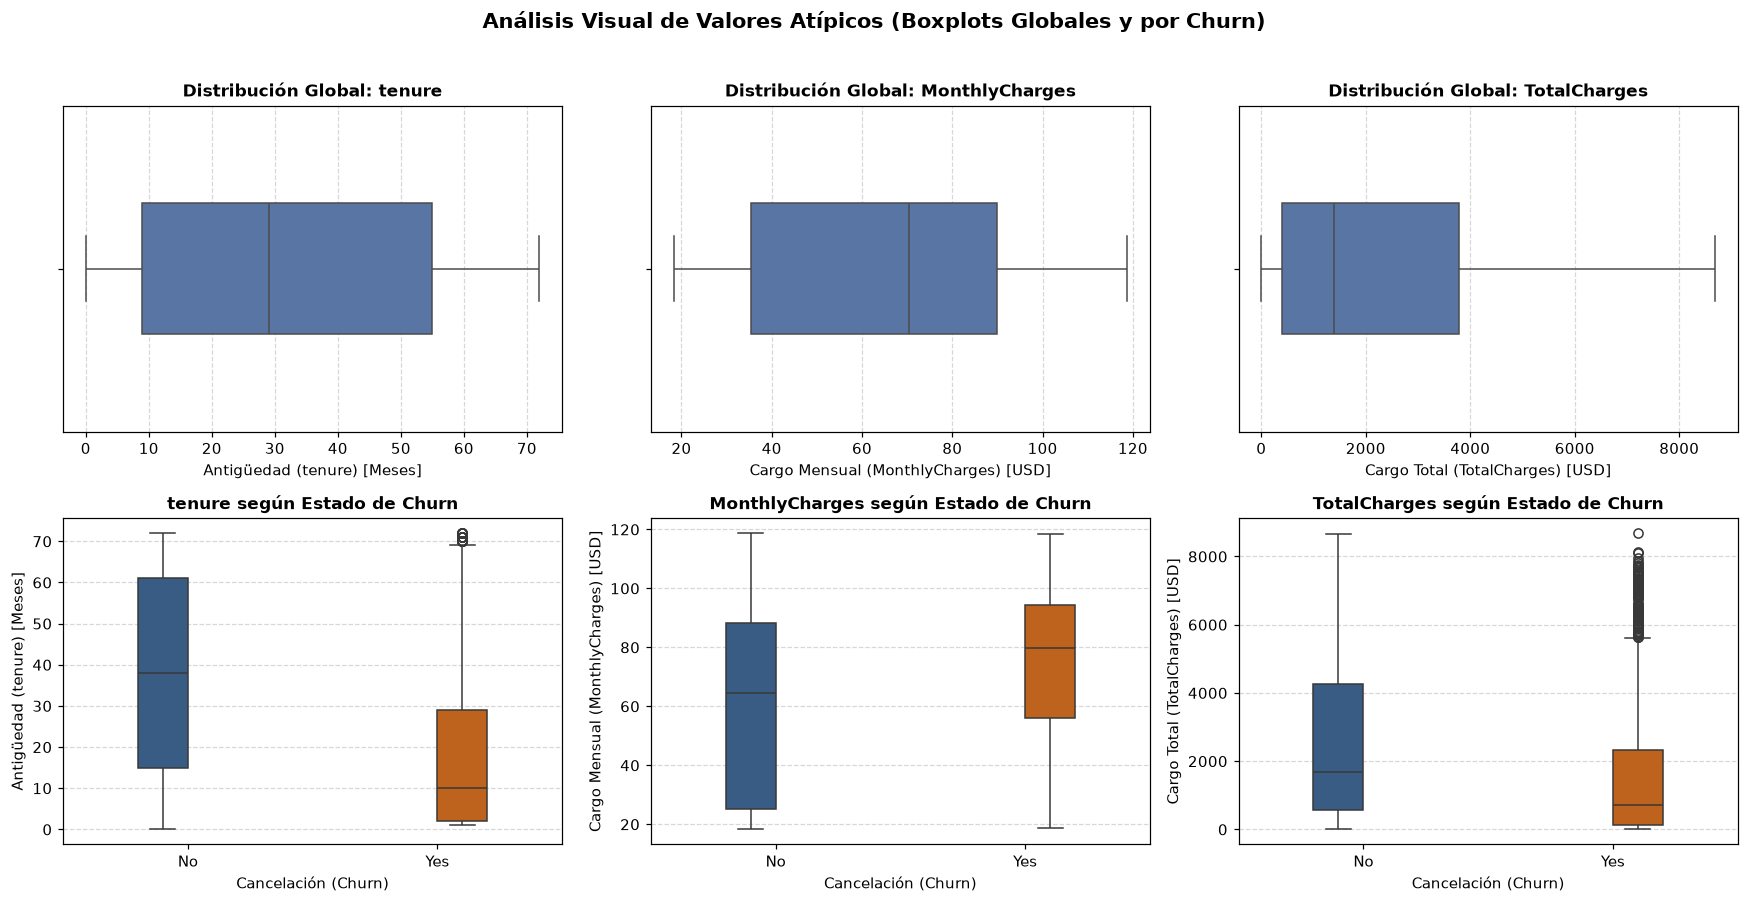

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
paleta_churn = {"No": "#2b5c8f", "Yes": "#d95f02"}

etiquetas = {
    "tenure": "Antigüedad (tenure) [Meses]",
    "MonthlyCharges": "Cargo Mensual (MonthlyCharges) [USD]",
    "TotalCharges": "Cargo Total (TotalCharges) [USD]"
}

for i, col in enumerate(cols_cuantitativas):
    sns.boxplot(x=df[col], ax=axes[0, i], color="#4c72b0", width=0.4)
    axes[0, i].set_title(f"Distribución Global: {col}", fontsize=11, fontweight="bold")
    axes[0, i].set_xlabel(etiquetas[col])
    axes[0, i].grid(axis="x", linestyle="--", alpha=0.5)

for i, col in enumerate(cols_cuantitativas):
    sns.boxplot(
        data=df, x="Churn", y=col, ax=axes[1, i],
        hue="Churn", palette=paleta_churn, legend=False, width=0.4
    )
    axes[1, i].set_title(f"{col} según Estado de Churn", fontsize=11, fontweight="bold")
    axes[1, i].set_xlabel("Cancelación (Churn)")
    axes[1, i].set_ylabel(etiquetas[col])
    axes[1, i].grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle("Análisis Visual de Valores Atípicos (Boxplots Globales y por Churn)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

#### Justificación Metodológica del Tratamiento y Conservación de Registros

1. **Ausencia de outliers univariados globales:** Como demuestra la tabla analítica IQR y la fila superior de gráficos, ninguna de las tres variables presenta valores fuera del intervalo $[Q_1 - 1.5 \times IQR, Q_3 + 1.5 \times IQR]$. Los valores máximos observados (`72` meses, `$118.75` mensuales y `$8,684.80` acumulados) son completamente consistentes con la escala tarifaria y el horizonte de 6 años del dataset.
2. **Explicación de los valores extremos condicionales en `TotalCharges` (`Churn = Yes`):** En el gráfico inferior derecho (`TotalCharges` segmentado por `Churn`), aparecen puntos individuales sobre el bigote superior dentro del grupo que canceló (`Yes`). Esto sucede porque la mayoría de las bajas ocurren temprano (mediana de 10 meses y $Q_3$ bajo), lo que estrecha la caja de ese subgrupo. Esos puntos superiores corresponden a **clientes antiguos con paquetes premium que se dieron de baja después de 50 a 72 meses**.
3. **Decisión:** **Se conservan el 100% de las observaciones (7,043 filas).** No se aplica recorte (*trimming*) ni winsorización porque no existen errores de carga, y eliminar a los clientes de alta facturación que cancelaron ocultaría justamente los casos de pérdida más costosos para la compañía.

Finalmente, se actualiza el archivo exportado en `data/processed/telco_churn_clean.csv` para que incluya las nuevas variables calculadas.

In [25]:
os.makedirs(RUTA_PROCESSED, exist_ok=True)
df.to_csv(ARCHIVO_LIMPIO, index=False)
print(f"Dataset actualizado en {ARCHIVO_LIMPIO} con {df.shape[0]} filas y {df.shape[1]} columnas.")

Dataset actualizado en ../data/processed\telco_churn_clean.csv con 7043 filas y 27 columnas.


---

## 4. Análisis Exploratorio de Datos (EDA) y Estadística Aplicada

> **Responsable:** Juan Antuñez.

**Objetivo:** desarrollar el análisis estadístico cuantitativo (medidas de tendencia central, dispersión, posición y correlación lineal de Pearson entre `tenure`, `MonthlyCharges` y `TotalCharges`) y el análisis categórico (frecuencias absolutas, relativas y tablas de contingencia frente al `Churn`).

### 4.1 Análisis Cuantitativo: Medidas de Tendencia Central y Dispersión

Se determinan los estadísticos descriptivos para las variables numéricas principales y se contrastan sus valores entre los clientes retenidos (`Churn = No`) y los clientes que abandonaron (`Churn = Yes`).

In [26]:
# 1. Tabla integral de medidas de tendencia central, dispersión y forma
estadisticos_descriptivos = pd.DataFrame({
    "Media": df[cols_cuantitativas].mean(),
    "Mediana": df[cols_cuantitativas].median(),
    "Moda": [df[c].mode().iloc[0] for c in cols_cuantitativas],
    "Desv. Estándar (s)": df[cols_cuantitativas].std(),
    "Varianza (s²)": df[cols_cuantitativas].var(),
    "Mínimo": df[cols_cuantitativas].min(),
    "Máximo": df[cols_cuantitativas].max(),
    "Rango": df[cols_cuantitativas].max() - df[cols_cuantitativas].min(),
    "IQR": df[cols_cuantitativas].quantile(0.75) - df[cols_cuantitativas].quantile(0.25),
    "Coef. Variación (%)": (df[cols_cuantitativas].std() / df[cols_cuantitativas].mean()) * 100,
    "Asimetría (Skew)": df[cols_cuantitativas].skew()
}).round(2)

print("--- Medidas de Tendencia Central y Dispersión (Cartera Total) ---")
display(estadisticos_descriptivos)

# 2. Estadísticos comparativos condicionados por la variable objetivo Churn
print("\n--- Comparación de Tendencia Central y Dispersión según Churn ---")
comparativa_churn_num = df.groupby("Churn", observed=False)[cols_cuantitativas].agg(
    ["mean", "median", "std", lambda x: x.quantile(0.75) - x.quantile(0.25)]
).rename(columns={"mean": "Media", "median": "Mediana", "std": "Desv_Est", "<lambda_0>": "IQR"}).round(2)

display(comparativa_churn_num)

--- Medidas de Tendencia Central y Dispersión (Cartera Total) ---

--- Comparación de Tendencia Central y Dispersión según Churn ---


,Media,Mediana,Moda,Desv. Estándar (s),Varianza (s²),Mínimo,Máximo,Rango,IQR,Coef. Variación (%),Asimetría (Skew)
tenure,32.37,29.00,1.00,24.56,603.17,0.00,72.00,72.0,46.00,75.87,0.24
MonthlyCharges,64.76,70.35,20.05,30.09,905.41,18.25,118.75,100.5,54.35,46.46,-0.22
TotalCharges,2279.73,1394.55,0.00,2266.79,5138357.17,0.00,8684.80,8684.8,3388.05,99.43,0.96


tenure                        MonthlyCharges                         TotalCharges                           
       Media Mediana Desv_Est   IQR          Media Mediana Desv_Est    IQR        Media  Mediana Desv_Est      IQR
Churn                                                                                                             
No     37.57    38.0    24.11  46.0          61.27   64.43    31.09  63.30      2549.91  1679.52  2329.95  3689.95
Yes    17.98    10.0    19.53  27.0          74.44   79.65    24.67  38.05      1531.80   703.55  1890.82  2196.80

**Interpretación estadística aplicada al negocio:**
- **Antigüedad (`tenure`):** Tiene una **media de 32.37 meses** y una **mediana de 29.00 meses**, pero su **moda es de apenas 1 mes** (alta concentración de altas recientes) y exhibe una dispersión elevada ($CV = 75.87\%$, $s = 24.56$ meses). Al segmentar por `Churn`, la diferencia es contundente: la mediana de permanencia de quienes cancelan es de **10 meses** (media 17.98), frente a una mediana de **38 meses** (media 37.57) en quienes continúan activos.
- **Cargos Mensuales (`MonthlyCharges`):** Presenta una **media de $64.76** inferior a su **mediana de $70.35** (asimetría negativa de `-0.22`), con una moda de **$20.05** correspondiente al abono telefónico básico y una dispersión relativa moderada ($CV = 46.46\%$). Los clientes que se dan de baja abonan una **mediana de $79.65/mes** ($s = 24.67$), notablemente más alta que la **mediana de $64.43/mes** ($s = 31.09$) de los usuarios fieles.
- **Cargos Totales (`TotalCharges`):** Muestra una marcada **asimetría positiva (`0.96`)** y la mayor dispersión relativa del dataset ($CV = 99.43\%$). Debido a que los clientes antiguos con tarifas altas estiran la cola derecha de la distribución, la **media ($2,279.73)** supera ampliamente a la **mediana ($1,394.55)**. Estadísticamente, para esta variable **la mediana y el IQR ($3,388.05) son las medidas representativas adecuadas**, ya que la media se encuentra sesgada hacia arriba.

### 4.2 Análisis de Correlación Lineal de Pearson

Se calcula la matriz de correlación lineal mediante el **coeficiente de correlación de Pearson ($r$)** entre las variables cuantitativas `tenure`, `MonthlyCharges` y `TotalCharges` (y su relación con la variable objetivo `Churn_num`). El coeficiente $r$ varía entre $-1$ y $+1$: el **signo** indica la dirección de la relación (positiva o inversa) y la **magnitud** indica su fuerza (cercano a $0$ es débil, cercano a $1$ o $-1$ es fuerte).

In [27]:
# Matriz de correlación de Pearson
vars_correlacion = ["tenure", "MonthlyCharges", "TotalCharges", "Churn_num"]
matriz_pearson = df[vars_correlacion].corr(method="pearson").round(3)

print("--- Matriz de Correlación Lineal de Pearson (r) ---")
display(matriz_pearson)

# Resumen numérico compacto de los pares principales
pares = [
    ("tenure", "TotalCharges"),
    ("MonthlyCharges", "TotalCharges"),
    ("tenure", "MonthlyCharges"),
    ("tenure", "Churn_num"),
    ("MonthlyCharges", "Churn_num"),
    ("TotalCharges", "Churn_num")
]

tabla_pares = pd.DataFrame({
    "Variable 1": [p[0] for p in pares],
    "Variable 2": [p[1] for p in pares],
    "Pearson (r)": [matriz_pearson.loc[p[0], p[1]] for p in pares],
    "Signo": ["Positivo (+)" if matriz_pearson.loc[p[0], p[1]] > 0 else "Negativo (-)" for p in pares],
    "Magnitud": ["Fuerte", "Moderada-Alta", "Débil", "Moderada", "Débil", "Débil"]
})
display(tabla_pares)

--- Matriz de Correlación Lineal de Pearson (r) ---


,tenure,MonthlyCharges,TotalCharges,Churn_num
tenure,1.000,0.248,0.826,-0.352
MonthlyCharges,0.248,1.000,0.651,0.193
TotalCharges,0.826,0.651,1.000,-0.198
Churn_num,-0.352,0.193,-0.198,1.000


,Variable 1,Variable 2,Pearson (r),Signo,Magnitud
0,tenure,TotalCharges,0.826,Positivo (+),Fuerte
1,MonthlyCharges,TotalCharges,0.651,Positivo (+),Moderada-Alta
2,tenure,MonthlyCharges,0.248,Positivo (+),Débil
3,tenure,Churn_num,-0.352,Negativo (-),Moderada
4,MonthlyCharges,Churn_num,0.193,Positivo (+),Débil
5,TotalCharges,Churn_num,-0.198,Negativo (-),Débil


**Interpretación de signo, magnitud y significado de negocio:**
- **`tenure` vs. `TotalCharges` ($r = +0.826$, positiva fuerte):** Es la relación lineal más fuerte del dataset. Tiene sentido comercial directo porque el cargo total acumulado depende de cuántos meses lleva facturando el cliente.
- **`MonthlyCharges` vs. `TotalCharges` ($r = +0.651$, positiva moderada-alta):** Los clientes con abonos mensuales más caros acumulan una facturación total mayor a lo largo del tiempo.
- **`tenure` vs. `MonthlyCharges` ($r = +0.248$, positiva débil):** Muestra que la antigüedad del cliente casi no influye en el precio de su tarifa mensual actual.
- **Relación con `Churn_num`:** La antigüedad tiene una correlación **negativa moderada ($r = -0.352$)** con la baja (a mayor antigüedad, menor probabilidad de cancelar), mientras que el cargo mensual tiene una correlación **positiva ($r = +0.193$)** (a mayor tarifa mensual, mayor tendencia a darse de baja).

### 4.3 Análisis Categórico: Frecuencias Absolutas, Relativas y Tablas de Contingencia

Se evalúa la distribución univariada (frecuencias absolutas $n_i$ y relativas $f_i\%$) y bivariada (tablas de contingencia cruzadas contra `Churn` mediante `pd.crosstab`) para dos bloques de atributos:
1. **Características Sociodemográficas:** `gender`, `SeniorCitizen`, `Partner`, `Dependents`.
2. **Características de Contratación y Servicios:** `Contract`, `InternetService`, `PaymentMethod`, `PaperlessBilling`, `OnlineSecurity`, `TechSupport`.

In [28]:
def analizar_variable_categorica(dataframe, col):
    """
    Calcula frecuencias absolutas, frecuencias relativas (%) 
    y tabla de contingencia porcentual contra Churn.
    """
    # Tabla de contingencia absoluta (sin el argumento 'observed' para compatibilidad total)
    ct_abs = pd.crosstab(dataframe[col], dataframe["Churn"])
    total_cat = ct_abs.sum(axis=1)
    
    # Frecuencia relativa respecto al total de clientes (7043)
    frec_rel_total = (total_cat / len(dataframe) * 100).round(2)
    
    # Tabla de contingencia relativa por fila 
    ct_rel_fila = (pd.crosstab(dataframe[col], dataframe["Churn"], normalize="index") * 100).round(2)
    
    tabla_final = pd.DataFrame({
        "No_Churn (n)": ct_abs["No"],
        "Yes_Churn (n)": ct_abs["Yes"],
        "Total_Clientes": total_cat,
        "%_del_Total": frec_rel_total,
        "%_Retencion (No)": ct_rel_fila["No"],
        "%_Tasa_Churn (Yes)": ct_rel_fila["Yes"]
    })
    return tabla_final

# Variables Sociodemográficas
cols_demograficas = ["gender", "SeniorCitizen", "Partner", "Dependents"]

for c in cols_demograficas:
    print(f"\n>>> Variable: {c}")
    display(analizar_variable_categorica(df, c))


>>> Variable: gender

>>> Variable: SeniorCitizen

>>> Variable: Partner

>>> Variable: Dependents


,No_Churn (n),Yes_Churn (n),Total_Clientes,%_del_Total,%_Retencion (No),%_Tasa_Churn (Yes)
gender,,,,,,
Female,2549,939,3488,49.52,73.08,26.92
Male,2625,930,3555,50.48,73.84,26.16


,No_Churn (n),Yes_Churn (n),Total_Clientes,%_del_Total,%_Retencion (No),%_Tasa_Churn (Yes)
SeniorCitizen,,,,,,
0,4508,1393,5901,83.79,76.39,23.61
1,666,476,1142,16.21,58.32,41.68


,No_Churn (n),Yes_Churn (n),Total_Clientes,%_del_Total,%_Retencion (No),%_Tasa_Churn (Yes)
Partner,,,,,,
No,2441,1200,3641,51.7,67.04,32.96
Yes,2733,669,3402,48.3,80.34,19.66


,No_Churn (n),Yes_Churn (n),Total_Clientes,%_del_Total,%_Retencion (No),%_Tasa_Churn (Yes)
Dependents,,,,,,
No,3390,1543,4933,70.04,68.72,31.28
Yes,1784,326,2110,29.96,84.55,15.45


In [29]:
# Variables de Contratación, Facturación y Soporte
cols_contratacion = [
    "Contract", "InternetService", "PaymentMethod", 
    "PaperlessBilling", "OnlineSecurity", "TechSupport"
]

for c in cols_contratacion:
    print(f"\n>>> Variable: {c}")
    display(analizar_variable_categorica(df, c))


>>> Variable: Contract

>>> Variable: InternetService

>>> Variable: PaymentMethod

>>> Variable: PaperlessBilling

>>> Variable: OnlineSecurity

>>> Variable: TechSupport


,No_Churn (n),Yes_Churn (n),Total_Clientes,%_del_Total,%_Retencion (No),%_Tasa_Churn (Yes)
Contract,,,,,,
Month-to-month,2220,1655,3875,55.02,57.29,42.71
One year,1307,166,1473,20.91,88.73,11.27
Two year,1647,48,1695,24.07,97.17,2.83


,No_Churn (n),Yes_Churn (n),Total_Clientes,%_del_Total,%_Retencion (No),%_Tasa_Churn (Yes)
InternetService,,,,,,
DSL,1962,459,2421,34.37,81.04,18.96
Fiber optic,1799,1297,3096,43.96,58.11,41.89
No,1413,113,1526,21.67,92.60,7.40


,No_Churn (n),Yes_Churn (n),Total_Clientes,%_del_Total,%_Retencion (No),%_Tasa_Churn (Yes)
PaymentMethod,,,,,,
Bank transfer (automatic),1286,258,1544,21.92,83.29,16.71
Credit card (automatic),1290,232,1522,21.61,84.76,15.24
Electronic check,1294,1071,2365,33.58,54.71,45.29
Mailed check,1304,308,1612,22.89,80.89,19.11


,No_Churn (n),Yes_Churn (n),Total_Clientes,%_del_Total,%_Retencion (No),%_Tasa_Churn (Yes)
PaperlessBilling,,,,,,
No,2403,469,2872,40.78,83.67,16.33
Yes,2771,1400,4171,59.22,66.43,33.57


,No_Churn (n),Yes_Churn (n),Total_Clientes,%_del_Total,%_Retencion (No),%_Tasa_Churn (Yes)
OnlineSecurity,,,,,,
No,2037,1461,3498,49.67,58.23,41.77
No internet service,1413,113,1526,21.67,92.60,7.40
Yes,1724,295,2019,28.67,85.39,14.61


,No_Churn (n),Yes_Churn (n),Total_Clientes,%_del_Total,%_Retencion (No),%_Tasa_Churn (Yes)
TechSupport,,,,,,
No,2027,1446,3473,49.31,58.36,41.64
No internet service,1413,113,1526,21.67,92.60,7.40
Yes,1734,310,2044,29.02,84.83,15.17


### 4.4 Síntesis Analítica del EDA y Contraste de Hipótesis

| Hipótesis / Dimensión | Evidencia Estadística Obtenida | Conclusión de Negocio |
|---|---|---|
| **H1: Tipo de Contrato** | `Month-to-month` (55.02% de la cartera) tiene **42.71% de churn**, frente a **11.27%** en `One year` y **2.83%** en `Two year`. | **Hipótesis Validada.** La falta de compromiso contractual a plazo es el principal predictor categórico de fuga. |
| **H2: Cargos Mensuales y Antigüedad** | Quienes cancelan tienen una mediana de `tenure` de **10 meses** (vs. 38 en activos) y una mediana de `MonthlyCharges` de **$79.65** (vs. $64.43 en activos). Correlación `tenure–Churn` de **-0.352**. | **Hipótesis Validada.** El abandono se concentra en los primeros 12 meses y afecta desproporcionadamente a tarifas altas. |
| **H3: Servicios de Valor Añadido** | Sin `OnlineSecurity` la baja es del **41.77%** (con el servicio baja a **14.61%**). Sin `TechSupport` es del **41.64%** (con soporte baja a **15.17%**). | **Hipótesis Validada.** Los servicios de seguridad y asistencia técnica reducen la tasa de cancelación a casi un tercio. |
| **Facturación y Medio de Pago** | `Electronic check` (33.58% del padrón) presenta **45.29% de churn**, mientras que los medios automáticos rondan el **15%–16%**. | El cobro manual por cheque electrónico genera fricción mensual; migrar clientes a débito automático es prioritario. |
| **Perfil Sociodemográfico** | `gender` es neutro (~26.5% en ambos). `SeniorCitizen = 1` alcanza **41.68% de churn** y clientes sin dependientes un **31.28%**. | Focalizar planes de retención específicos para adultos mayores y hogares sin grupo familiar a cargo. |

---

## 5. Visualización de Datos

> **Responsable:** Alejo.

**Objetivo:** construir el reporte gráfico exigido por la consigna con **Matplotlib** y **Seaborn**:

1. **Histogramas con KDE** de la antigüedad (`tenure`) y de los cargos mensuales (`MonthlyCharges`).
2. **Diagramas de barras comparativos** de la **tasa de cancelación (Churn)** según el **tipo de contrato** y la **modalidad de pago**.

> La matriz de correlación (*heatmap*) corresponde a la **Sección 6**.

Cada gráfico va acompañado de una **interpretación orientada al impacto en el negocio**. Las cifras citadas provienen de las tablas de las secciones 4.1 y 4.3.

**Cómo leer un histograma con KDE:** el histograma agrupa a los clientes en intervalos (*bins*) y muestra cuántos hay en cada uno; la curva **KDE** (*Kernel Density Estimation*) es una versión suavizada de esa distribución, que ayuda a ver su forma (picos, colas, simetría).

### 5.1 Histogramas y KDE de `tenure` y `MonthlyCharges`

Se marcan con líneas verticales la **media** (línea punteada negra) y la **mediana** (línea punteada gris). Cuando ambas se separan, la distribución es **asimétrica**.


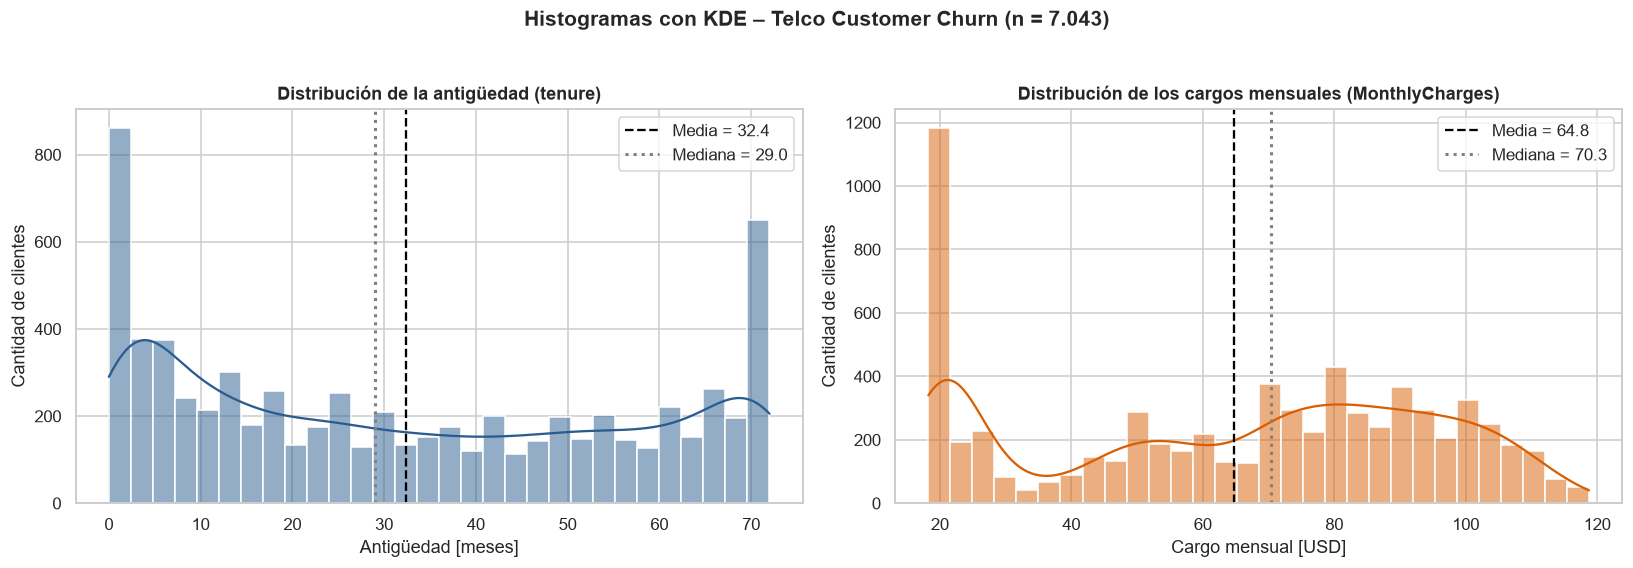

In [30]:
sns.set_theme(style="whitegrid")

configuracion = [
    ("tenure", "#2b5c8f", "Distribución de la antigüedad (tenure)", "Antigüedad [meses]"),
    ("MonthlyCharges", "#d95f02", "Distribución de los cargos mensuales (MonthlyCharges)", "Cargo mensual [USD]"),
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, (col, color, titulo, etiqueta_x) in zip(axes, configuracion):
    sns.histplot(df[col], bins=30, kde=True, color=color, edgecolor="white", ax=ax)
    ax.axvline(df[col].mean(), color="black", linestyle="--", linewidth=1.5,
               label=f"Media = {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="gray", linestyle=":", linewidth=2,
               label=f"Mediana = {df[col].median():.1f}")
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel("Cantidad de clientes")
    ax.legend()

plt.suptitle("Histogramas con KDE – Telco Customer Churn (n = 7.043)", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


**Interpretación (impacto en el negocio):**

- **Antigüedad (`tenure`):** la distribución **no tiene forma de campana**: concentra clientes en los **extremos** (muchos recién llegados, con moda de apenas 1 mes, y también un grupo grande de clientes con unos 72 meses). La media (32,37 meses) es algo mayor que la mediana (29 meses) y la dispersión es alta (CV = 75,87 %). **Lectura de negocio:** la cartera combina dos poblaciones muy distintas, una base **nueva** y una base **fidelizada**, y no se las puede tratar con una única estrategia.
- **Cargos mensuales (`MonthlyCharges`):** hay un **pico marcado cerca de USD 20** (moda = 20,05, plan básico de telefonía) y el resto de los clientes se reparte entre cargos medios y altos. La media (USD 64,76) queda por debajo de la mediana (USD 70,35), lo que indica una leve **asimetría negativa** (−0,22) causada por ese grupo de planes baratos. **Lectura de negocio:** la empresa tiene un segmento de **bajo costo** muy numeroso y otro de **alto valor** con servicios adicionales; los ingresos mensuales dependen mucho de este segundo grupo.

### 5.2 Distribución de `tenure` y `MonthlyCharges` según Churn (KDE comparado)

Para vincular las distribuciones con el problema de negocio, se superpone la curva KDE de los clientes que **continúan** (`No`) y de los que **cancelaron** (`Yes`). Con `common_norm=False` cada curva se normaliza por separado, así que se compara la **forma** de cada grupo sin que el grupo más numeroso (los que continúan) domine el gráfico.


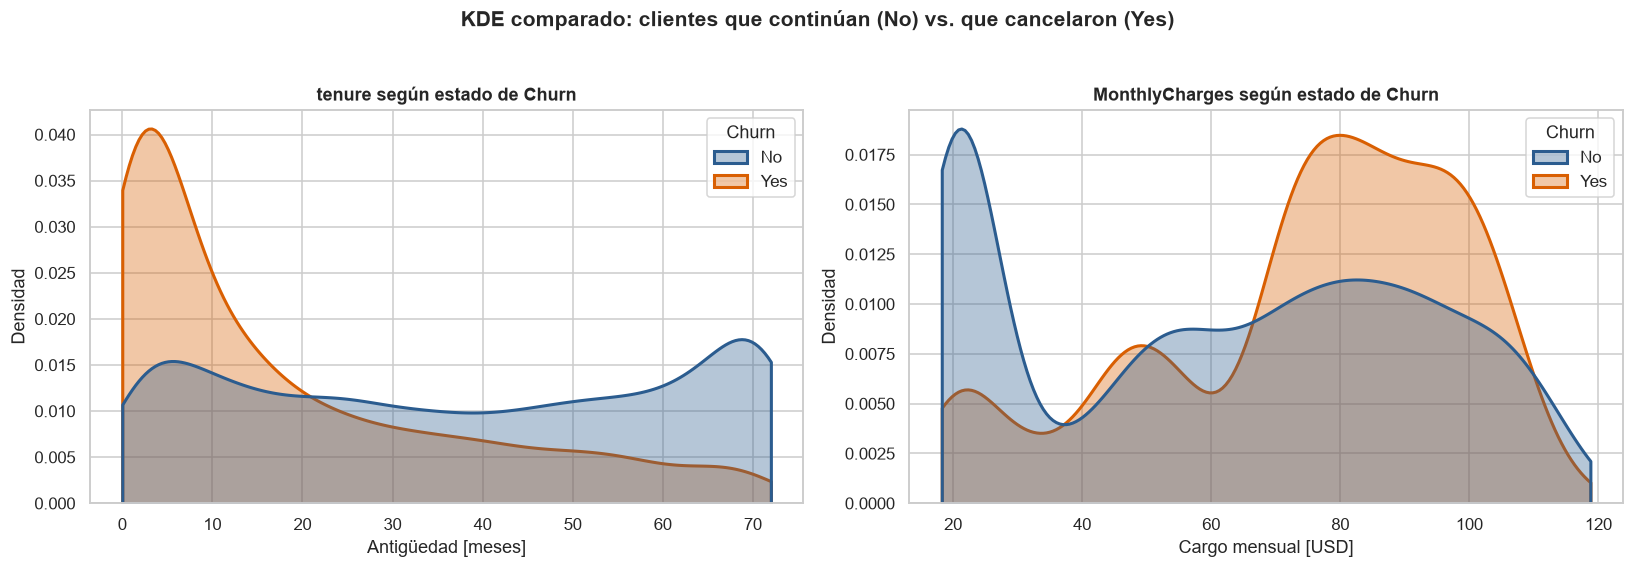

In [31]:
paleta_churn = {"No": "#2b5c8f", "Yes": "#d95f02"}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, (col, _, _, etiqueta_x) in zip(axes, configuracion):
    sns.kdeplot(
        data=df, x=col, hue="Churn", hue_order=["No", "Yes"],
        palette=paleta_churn, fill=True, alpha=0.35, linewidth=2,
        common_norm=False, clip=(df[col].min(), df[col].max()), ax=ax,
    )
    ax.set_title(f"{col} según estado de Churn", fontsize=12, fontweight="bold")
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel("Densidad")

plt.suptitle("KDE comparado: clientes que continúan (No) vs. que cancelaron (Yes)", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


**Interpretación (impacto en el negocio):**

- **`tenure`:** la curva de los clientes que **cancelaron** se concentra en los **primeros meses** (mediana de 10 meses), mientras que la de los que **continúan** se desplaza hacia la derecha (mediana de 38 meses). **Lectura de negocio:** el riesgo de baja es máximo al comienzo de la relación con el cliente, por lo que las acciones de retención (onboarding, beneficios iniciales) deben concentrarse en el **primer año**.
- **`MonthlyCharges`:** la curva de las bajas se ubica más a la derecha (mediana de USD 79,65 contra USD 64,43 de los clientes que continúan), y el pico de USD 20 casi no aparece entre quienes cancelan. **Lectura de negocio:** el abandono se da sobre todo en **planes de cargo medio-alto**, no en el plan básico; perder un cliente de ese perfil es más costoso porque es el que más aporta por mes.

### 5.3 Tasa de cancelación (Churn) por tipo de contrato y modalidad de pago

La **tasa de Churn** de un grupo es el porcentaje de clientes de ese grupo que canceló. Como `Churn_num` vale 1 para las bajas y 0 para el resto (Sección 1.7), su **promedio** por grupo es directamente esa tasa.

La línea roja punteada indica la **tasa general de la empresa** (26,54 %): las barras **naranjas** superan ese promedio y las **azules** quedan por debajo.


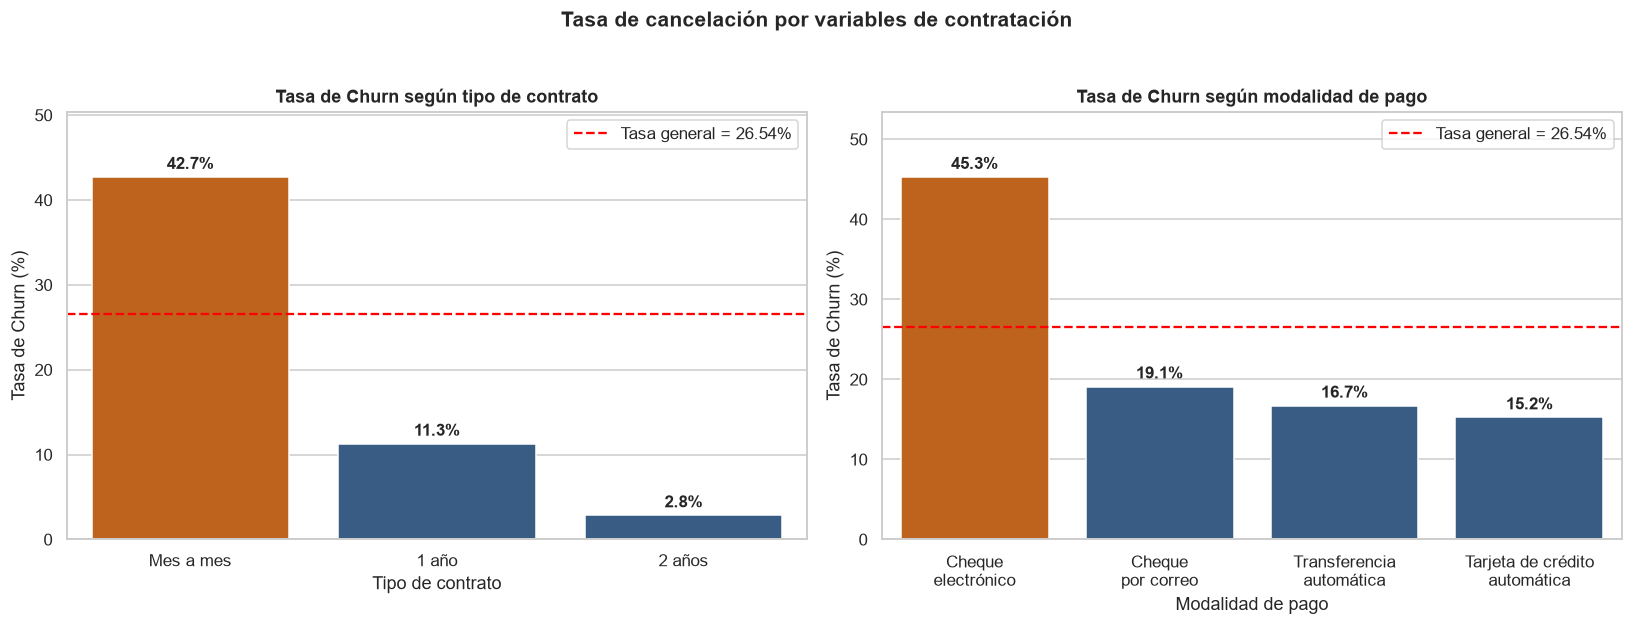

In [32]:
tasa_global = df["Churn_num"].mean() * 100

# Tasa de Churn (%) por grupo. Contract es categórica ordinal, por lo que conserva su orden lógico.
tasa_contrato = df.groupby("Contract", observed=False)["Churn_num"].mean() * 100
tasa_pago = (df.groupby("PaymentMethod", observed=False)["Churn_num"].mean() * 100).sort_values(ascending=False)

etiquetas_contrato = {"Month-to-month": "Mes a mes", "One year": "1 año", "Two year": "2 años"}
etiquetas_pago = {
    "Electronic check": "Cheque\nelectrónico",
    "Mailed check": "Cheque\npor correo",
    "Bank transfer (automatic)": "Transferencia\nautomática",
    "Credit card (automatic)": "Tarjeta de crédito\nautomática",
}

def grafico_barras_churn(ax, tasas, etiquetas, titulo, xlabel):
    nombres = [etiquetas[g] for g in tasas.index]
    colores = {n: ("#d95f02" if t > tasa_global else "#2b5c8f") for n, t in zip(nombres, tasas.values)}
    sns.barplot(x=nombres, y=tasas.values, hue=nombres, palette=colores, legend=False, ax=ax)
    ax.axhline(tasa_global, color="red", linestyle="--", linewidth=1.5,
               label=f"Tasa general = {tasa_global:.2f}%")
    for barra in ax.patches:
        if barra.get_height() > 0:
            ax.annotate(f"{barra.get_height():.1f}%",
                        (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                        ha="center", va="bottom", fontsize=11, fontweight="bold",
                        xytext=(0, 3), textcoords="offset points")
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Tasa de Churn (%)")
    ax.set_ylim(0, max(tasas.max() * 1.18, tasa_global * 1.3))
    ax.legend(loc="upper right")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
grafico_barras_churn(axes[0], tasa_contrato, etiquetas_contrato,
                     "Tasa de Churn según tipo de contrato", "Tipo de contrato")
grafico_barras_churn(axes[1], tasa_pago, etiquetas_pago,
                     "Tasa de Churn según modalidad de pago", "Modalidad de pago")

plt.suptitle("Tasa de cancelación por variables de contratación", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()
sns.reset_defaults()  # restaura estilo base para las secciones siguientes


In [33]:
# Tabla de respaldo de los gráficos: cantidad de clientes, bajas y diferencia contra la tasa general
def resumen_churn(columna):
    r = df.groupby(columna, observed=False).agg(
        Clientes=("Churn_num", "count"),
        Bajas=("Churn_num", "sum"),
        Tasa_Churn_Pct=("Churn_num", lambda x: round(x.mean() * 100, 2)),
    )
    r["Dif_vs_general_(pp)"] = (r["Tasa_Churn_Pct"] - round(tasa_global, 2)).round(2)
    return r.sort_values("Tasa_Churn_Pct", ascending=False)

print(f"Tasa de Churn general: {tasa_global:.2f}%\n")
print("--- Por tipo de contrato ---")
display(resumen_churn("Contract"))
print("\n--- Por modalidad de pago ---")
display(resumen_churn("PaymentMethod"))


Tasa de Churn general: 26.54%

--- Por tipo de contrato ---

--- Por modalidad de pago ---


,Clientes,Bajas,Tasa_Churn_Pct,Dif_vs_general_(pp)
Contract,,,,
Month-to-month,3875,1655,42.71,16.17
One year,1473,166,11.27,-15.27
Two year,1695,48,2.83,-23.71


,Clientes,Bajas,Tasa_Churn_Pct,Dif_vs_general_(pp)
PaymentMethod,,,,
Electronic check,2365,1071,45.29,18.75
Mailed check,1612,308,19.11,-7.43
Bank transfer (automatic),1544,258,16.71,-9.83
Credit card (automatic),1522,232,15.24,-11.30


**Interpretación (impacto en el negocio):**

- **Tipo de contrato:** la tasa de baja baja de forma escalonada a medida que aumenta el compromiso: **42,71 %** en `Month-to-month`, **11,27 %** en `One year` y **2,83 %** en `Two year`. Los clientes mes a mes abandonan unas **15 veces más** que los de contrato de 2 años, y además son el **55 %** de la cartera. **Recomendación:** ofrecer descuentos o beneficios por pasar de mensual a contrato anual o bianual, sobre todo en los primeros 12 meses.
- **Modalidad de pago:** el **cheque electrónico** destaca con **45,29 %** de Churn, muy por encima de la tasa general (26,54 %) y de los medios automáticos (**16,71 %** con transferencia y **15,24 %** con tarjeta); el cheque por correo queda en **19,11 %**. Además, el cheque electrónico es el medio de pago de **1 de cada 3** clientes (33,58 %). **Recomendación:** incentivar la migración al **débito automático**, que elimina la fricción del pago manual todos los meses.
- **Cautela:** estas son asociaciones observadas en datos históricos y **no prueban causalidad**. Por ejemplo, quienes tienen contrato anual o bianual pueden ser clientes que ya estaban más comprometidos con la empresa desde antes.

### 5.4 Síntesis de la sección

| Gráfico | Hallazgo principal | Acción de negocio sugerida |
|---|---|---|
| Histograma/KDE de `tenure` | Dos poblaciones: base nueva y base fidelizada; las bajas se concentran en los primeros meses (mediana 10 vs. 38). | Programa de retención para el **primer año**. |
| Histograma/KDE de `MonthlyCharges` | Pico en el plan básico (~USD 20) y bajas en planes de cargo medio-alto (mediana USD 79,65). | Proteger a los clientes de **planes medios y altos**. |
| Churn por contrato | Mes a mes 42,71 % vs. 2 años 2,83 %. | Migrar clientes a **contratos de mayor plazo**. |
| Churn por modalidad de pago | Cheque electrónico 45,29 % vs. pagos automáticos ≈ 15–17 %. | Promover el **pago automático**. |


---

## 6. Matriz y Heatmap de Correlación Lineal

> **Responsable:** Sebastian.

**Objetivo:** representar gráficamente, mediante un **mapa de calor (heatmap)**, la matriz de correlación de Pearson entre las variables numéricas `tenure`, `MonthlyCharges` y `TotalCharges`, e interpretar la **magnitud**, el **signo** y el **impacto de negocio** de las relaciones observadas.

En la **Sección 4.2** se calcularon los coeficientes. Esta sección agrega:
1. La **significancia estadística** de cada coeficiente (p-valor) y la proporción de varianza compartida ($R^2$).
2. El **heatmap etiquetado** exigido por la consigna.
3. Un heatmap **ampliado** que incorpora la variable objetivo (`Churn_num`) y las columnas calculadas en la Sección 2.3.
4. **Diagramas de dispersión** para ver la *forma* de cada relación y un **control de robustez** con Spearman.

**Coeficiente de correlación de Pearson:**

$$r_{xy} = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\;\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}} \qquad -1 \le r \le 1$$

| Valor absoluto de $r$ | Fuerza de la relación lineal |
|---|---|
| $< 0{,}30$ | Débil |
| $0{,}30 - 0{,}70$ | Moderada |
| $> 0{,}70$ | Fuerte |

**Limitaciones:** Pearson solo mide relaciones **lineales**, es sensible a valores extremos y **correlación no implica causalidad**.

### 6.1 Matriz de correlación y significancia estadística

`df.corr(method="pearson")` calcula la matriz. `scipy.stats.pearsonr()` agrega el **p-valor** de cada par, es decir, la probabilidad de observar una correlación así si en realidad no existiera relación ($H_0: \rho = 0$). Con $\alpha = 0{,}05$, un p-valor menor indica una correlación estadísticamente significativa.

$R^2 = r^2$ es la **proporción de la variabilidad que comparten** las dos variables.

In [34]:
from scipy import stats

VARS_NUM = ["tenure", "MonthlyCharges", "TotalCharges"]
matriz_corr = df[VARS_NUM].corr(method="pearson")   # sin redondear: se usa para el heatmap

def clasificar_magnitud(r):
    a = abs(r)
    return "Débil" if a < 0.30 else ("Moderada" if a < 0.70 else "Fuerte")

filas = []
for i, var_a in enumerate(VARS_NUM):
    for var_b in VARS_NUM[i + 1:]:
        r, p = stats.pearsonr(df[var_a], df[var_b])
        filas.append({
            "Par de variables": f"{var_a} – {var_b}",
            "r de Pearson": round(r, 3),
            "R² (varianza compartida)": f"{r**2:.1%}",
            "Signo": "Positivo (+)" if r > 0 else "Negativo (-)",
            "Magnitud": clasificar_magnitud(r),
            "p-valor": f"{p:.1e}",
            "Significativa (α = 0,05)": "Sí" if p < 0.05 else "No",
        })

significancia_corr = pd.DataFrame(filas)
print(f"Clientes analizados: n = {len(df):,}")
display(significancia_corr)

Clientes analizados: n = 7,043


,Par de variables,r de Pearson,R² (varianza compartida),Signo,Magnitud,p-valor,"Significativa (α = 0,05)"
0,tenure – MonthlyCharges,0.248,6.1%,Positivo (+),Débil,4.1e-99,Sí
1,tenure – TotalCharges,0.826,68.3%,Positivo (+),Fuerte,0.0e+00,Sí
2,MonthlyCharges – TotalCharges,0.651,42.4%,Positivo (+),Moderada,0.0e+00,Sí


### 6.2 Heatmap de la matriz de correlación de Pearson

Se usa `sns.heatmap()` con:
- `annot=True` y `fmt=".2f"` → muestra el valor de $r$ en cada celda.
- `cmap="RdBu_r"` con `vmin=-1`, `vmax=1` y `center=0` → paleta divergente: **rojo** = correlación positiva, **azul** = negativa, **blanco** = sin relación. Fijar los extremos en $\pm1$ hace que la intensidad del color sea comparable con cualquier otra matriz.
- Etiquetas en español con la unidad de cada variable, para que el gráfico se lea sin conocer los nombres técnicos.

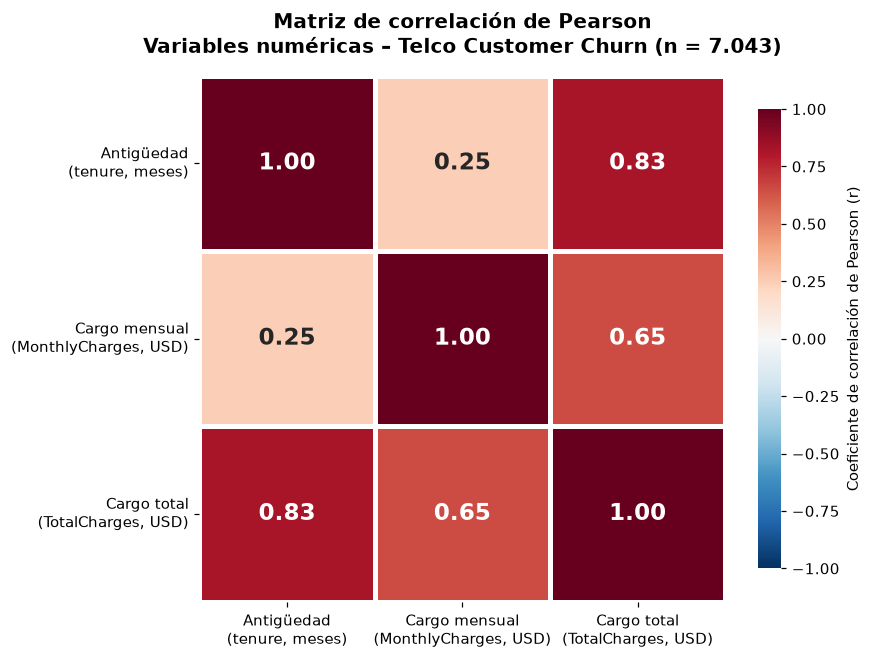

In [35]:
ETIQUETAS_CORR = {
    "tenure": "Antigüedad\n(tenure, meses)",
    "MonthlyCharges": "Cargo mensual\n(MonthlyCharges, USD)",
    "TotalCharges": "Cargo total\n(TotalCharges, USD)",
}

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(
    matriz_corr.rename(index=ETIQUETAS_CORR, columns=ETIQUETAS_CORR),
    annot=True, fmt=".2f", annot_kws={"size": 15, "weight": "bold"},
    cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
    linewidths=2, linecolor="white",
    cbar_kws={"label": "Coeficiente de correlación de Pearson (r)", "shrink": 0.8},
    ax=ax,
)
ax.set_title("Matriz de correlación de Pearson\nVariables numéricas – Telco Customer Churn (n = 7.043)",
             fontsize=13, fontweight="bold", pad=15)
ax.tick_params(axis="both", rotation=0, labelsize=10)
plt.tight_layout()
plt.show()

**Lectura del heatmap:**
- La diagonal vale **1,00** porque cada variable está perfectamente correlacionada consigo misma; la matriz es **simétrica** (el triángulo superior repite el inferior).
- Las tres correlaciones son **positivas** (todas las celdas en tonos rojos): ninguna variable disminuye cuando otra aumenta.
- **`tenure` – `TotalCharges` ($r = 0{,}83$, fuerte):** el rojo más intenso. Comparten cerca del **68 %** de su variabilidad.
- **`MonthlyCharges` – `TotalCharges` ($r = 0{,}65$, moderada):** comparten cerca del **42 %** de su variabilidad.
- **`tenure` – `MonthlyCharges` ($r = 0{,}25$, débil):** el tono más claro. Comparten solo el **6 %**: la antigüedad casi no anticipa cuánto paga un cliente por mes.

### 6.3 Heatmap ampliado: relación con el Churn y con las variables calculadas

Para vincular la correlación con el problema de negocio, se amplía la matriz con:
- **`Churn_num`** (variable objetivo codificada en la Sección 1.7: 1 = abandonó). Su correlación con una variable numérica es la **correlación punto-biserial**, un caso particular de Pearson.
- **`TotalServiciosAddons`** y **`RatioCostoAntiguedad`** (columnas calculadas en la Sección 2.3).

Se oculta el triángulo superior (`mask`) porque repite la misma información que el inferior.

Correlación de cada variable con Churn_num (ordenadas por magnitud):


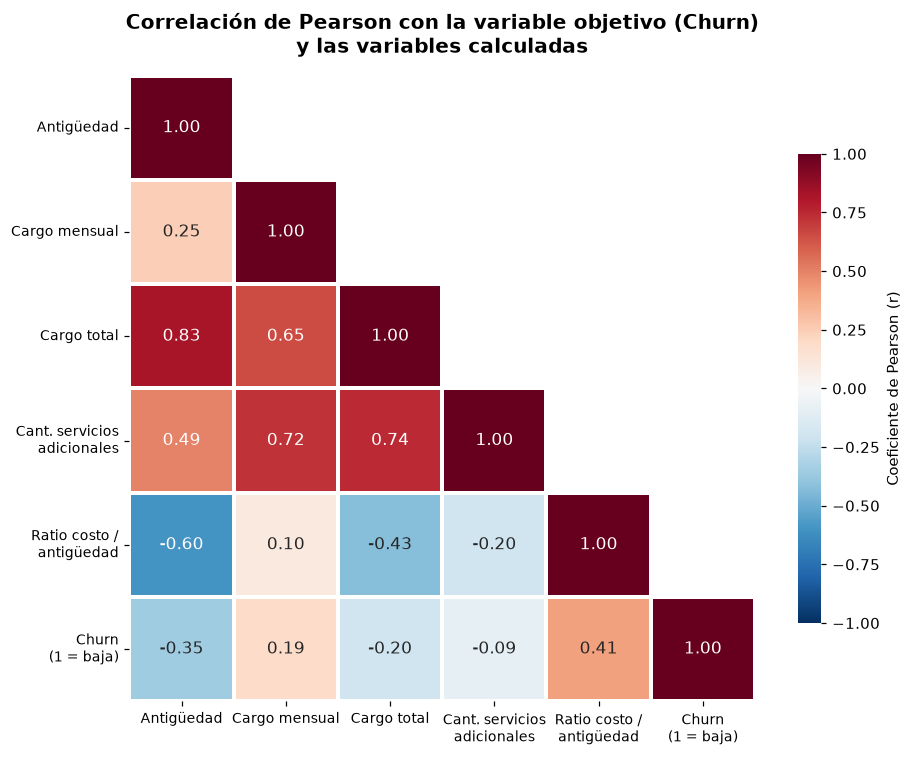

,r con Churn_num
RatioCostoAntiguedad,0.412
tenure,-0.352
TotalCharges,-0.198
MonthlyCharges,0.193
TotalServiciosAddons,-0.088


In [36]:
VARS_AMPLIADAS = ["tenure", "MonthlyCharges", "TotalCharges",
                  "TotalServiciosAddons", "RatioCostoAntiguedad", "Churn_num"]
matriz_ampliada = df[VARS_AMPLIADAS].corr(method="pearson")

mascara_superior = np.triu(np.ones_like(matriz_ampliada, dtype=bool), k=1)
etiquetas_ampliadas = {
    "tenure": "Antigüedad", "MonthlyCharges": "Cargo mensual", "TotalCharges": "Cargo total",
    "TotalServiciosAddons": "Cant. servicios\nadicionales", "RatioCostoAntiguedad": "Ratio costo /\nantigüedad",
    "Churn_num": "Churn\n(1 = baja)",
}

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    matriz_ampliada.rename(index=etiquetas_ampliadas, columns=etiquetas_ampliadas),
    mask=mascara_superior, annot=True, fmt=".2f", annot_kws={"size": 11},
    cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
    linewidths=1.5, linecolor="white",
    cbar_kws={"label": "Coeficiente de Pearson (r)", "shrink": 0.75}, ax=ax,
)
ax.set_title("Correlación de Pearson con la variable objetivo (Churn)\ny las variables calculadas",
             fontsize=13, fontweight="bold", pad=15)
ax.tick_params(axis="x", rotation=0, labelsize=9)
ax.tick_params(axis="y", rotation=0, labelsize=9)
plt.tight_layout()
plt.show()

print("Correlación de cada variable con Churn_num (ordenadas por magnitud):")
display(matriz_ampliada["Churn_num"].drop("Churn_num")
        .sort_values(key=abs, ascending=False).round(3).to_frame("r con Churn_num"))

**Lectura del heatmap ampliado (fila `Churn`):**
- **`RatioCostoAntiguedad` ($r \approx +0{,}41$)** es la variable numérica con mayor asociación con la baja: los clientes que pagan mucho **en relación con el poco tiempo que llevan** son los que más cancelan. Combina en un solo indicador los dos factores de la hipótesis H2.
- **`tenure` ($r \approx -0{,}35$):** relación **negativa moderada**. A mayor antigüedad, menor probabilidad de baja.
- **`MonthlyCharges` ($r \approx +0{,}19$):** relación **positiva débil**. Los cargos altos se asocian con más bajas.
- **`TotalCharges` ($r \approx -0{,}20$):** negativa débil. Arrastra el efecto de `tenure` (un cliente que se va pronto acumula poca facturación).
- **`TotalServiciosAddons` ($r \approx -0{,}09$):** prácticamente nula **como cantidad**. Esto no contradice la H3: la Sección 4.3 muestra que lo que protege es tener servicios **específicos** (`OnlineSecurity`, `TechSupport`), no sumar servicios de cualquier tipo (por ejemplo, streaming).
- La correlación **`TotalServiciosAddons` – `MonthlyCharges` ($r \approx 0{,}72$)** confirma que gran parte del precio mensual se explica por los servicios adicionales contratados.

### 6.4 Diagramas de dispersión: la forma de cada relación

El coeficiente $r$ resume una relación en un solo número, pero no muestra **cómo** se distribuyen los datos. Los diagramas de dispersión (coloreados por `Churn`, con la recta de ajuste lineal punteada) permiten verificar si una relación lineal es una buena descripción.

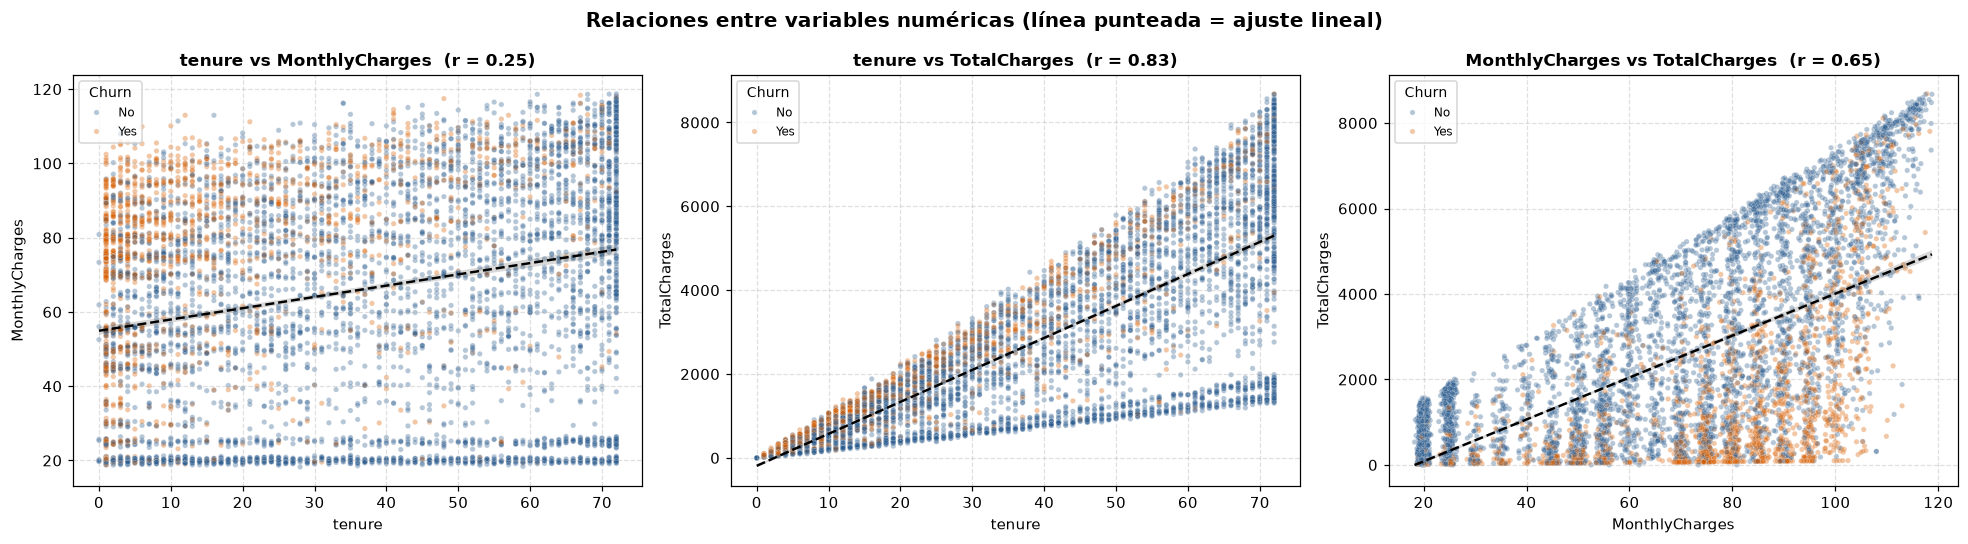

In [37]:
pares_dispersion = [("tenure", "MonthlyCharges"), ("tenure", "TotalCharges"), ("MonthlyCharges", "TotalCharges")]
paleta_churn = {"No": "#2b5c8f", "Yes": "#d95f02"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (x, y) in zip(axes, pares_dispersion):
    sns.scatterplot(data=df, x=x, y=y, hue="Churn", hue_order=["No", "Yes"],
                    palette=paleta_churn, alpha=0.35, s=12, ax=ax)
    sns.regplot(data=df, x=x, y=y, scatter=False, color="black",
                line_kws={"lw": 1.6, "ls": "--"}, ax=ax)
    ax.set_title(f"{x} vs {y}  (r = {matriz_corr.loc[x, y]:.2f})", fontsize=11, fontweight="bold")
    ax.legend(title="Churn", fontsize=8, title_fontsize=9)
    ax.grid(linestyle="--", alpha=0.4)

fig.suptitle("Relaciones entre variables numéricas (línea punteada = ajuste lineal)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación de los diagramas:**
- **`tenure` vs `TotalCharges`:** forma de **abanico** que parte del origen. Cada cliente se ubica sobre una recta cuya pendiente es su cargo mensual ($TotalCharges \approx tenure \times MonthlyCharges$, como se verificó con `FacturacionTeorica` en la Sección 2.3). Los puntos naranjas (bajas) se concentran a la izquierda: **clientes con poca antigüedad**.
- **`tenure` vs `MonthlyCharges`:** nube dispersa con una pendiente muy suave, coherente con $r = 0{,}25$. Se ven franjas horizontales que corresponden a los planes tarifarios: la franja de **≈ USD 20** (solo telefonía) está presente en todas las antigüedades y casi no tiene bajas, mientras que en la zona de **cargos altos y antigüedad baja** se concentran las cancelaciones.
- **`MonthlyCharges` vs `TotalCharges`:** el límite superior de la nube es el cliente con 72 meses de antigüedad. Las bajas se ubican en la **parte inferior derecha**: clientes de planes caros que se fueron antes de acumular facturación.

### 6.5 Control de robustez: Pearson vs. Spearman

El coeficiente de **Spearman** ($\rho$) mide relaciones **monótonas** (no necesariamente lineales) usando rangos en lugar de valores, por lo que es menos sensible a valores extremos y asimetrías como la de `TotalCharges`. Si ambos coeficientes son parecidos, las conclusiones de Pearson son confiables.

In [38]:
matriz_spearman = df[VARS_NUM].corr(method="spearman")

comparacion_metodos = pd.DataFrame({
    "Pearson (r)":   [matriz_corr.loc[a, b] for a, b in pares_dispersion],
    "Spearman (ρ)":  [matriz_spearman.loc[a, b] for a, b in pares_dispersion],
}, index=[f"{a} – {b}" for a, b in pares_dispersion]).round(3)
comparacion_metodos["Diferencia"] = (comparacion_metodos["Spearman (ρ)"] - comparacion_metodos["Pearson (r)"]).round(3)

display(comparacion_metodos)

,Pearson (r),Spearman (ρ),Diferencia
tenure – MonthlyCharges,0.248,0.276,0.028
tenure – TotalCharges,0.826,0.890,0.064
MonthlyCharges – TotalCharges,0.651,0.638,-0.013


Las diferencias son pequeñas y **no cambian ninguna clasificación de signo ni de magnitud**: la conclusión no depende del método. Spearman es algo mayor en `tenure – TotalCharges` (≈ 0,89) porque la relación es monótona pero no exactamente lineal (el abanico del gráfico anterior).

### 6.6 Conclusiones de la sección e impacto en el negocio

| Hallazgo | Implicancia para el negocio |
|---|---|
| `tenure` y `TotalCharges` están fuertemente correlacionadas ($r = 0{,}83$). | El ingreso total que deja un cliente depende sobre todo de **cuánto tiempo se queda**. Retener es la principal palanca del valor de vida del cliente (*Customer Lifetime Value*). |
| `MonthlyCharges` – `TotalCharges` es moderada ($r = 0{,}65$), menor que la de `tenure`. | Un plan caro no garantiza más ingresos si el cliente se va pronto. Un cliente de plan medio que permanece años aporta más que uno *premium* que cancela en los primeros meses. |
| `tenure` y `MonthlyCharges` casi no se relacionan ($r = 0{,}25$). | Son dimensiones **independientes** del cliente (permanencia y nivel de gasto), por lo que tiene sentido segmentar usando ambas. |
| `RatioCostoAntiguedad` (+0,41) y `tenure` (−0,35) son las variables numéricas más asociadas al Churn. | El grupo de mayor riesgo es el de **clientes nuevos con cargos altos**. Allí deben concentrarse las acciones de retención: onboarding, beneficios en los primeros 12 meses y migración a contratos anuales. |
| `TotalCharges` es en gran parte redundante con `tenure` × `MonthlyCharges`. | **Multicolinealidad:** en un futuro modelo predictivo no conviene usar las tres variables juntas sin tratamiento. |

> **Precaución:** son asociaciones observadas en datos históricos; **no prueban causalidad**. Por ejemplo, la correlación negativa entre antigüedad y Churn no implica que "esperar" reduzca el abandono, sino que los clientes que sobreviven el primer año tienden a quedarse.

---

## 7. Auditoría de Reproducibilidad en Google Colab

> **Responsable:** Sebastian.

**Objetivo:** garantizar que el notebook se ejecute **completo, de forma secuencial y sin errores** en un entorno limpio de Google Colab, como exige la consigna (componente *Colab, Repositorio Git e Informe*: 25 % de la nota).

### 7.1 Procedimiento de auditoría

1. Abrir el notebook desde el badge **"Open in Colab"** del `README.md` (no desde una copia local ni desde Drive).
2. `Entorno de ejecución → Desconectar y borrar el entorno de ejecución`: elimina variables, archivos temporales y librerías instaladas en sesiones anteriores.
3. `Entorno de ejecución → Ejecutar todas`.
4. Verificar que ninguna celda termine en error y que el contador de ejecución quede **correlativo desde 1** (`[1]`, `[2]`, `[3]`…), lo que demuestra que se corrió en orden y desde cero.
5. Contrastar las cifras clave con las citadas en las interpretaciones (tasa de churn 26,54 %, $r = 0{,}826$, etc.).
6. Ejecutar la celda de verificación automática (7.3), que debe finalizar con **✅**.

### 7.2 Checklist de buenas prácticas

| Control | Criterio | Estado |
|---|---|---|
| Rutas | Solo rutas relativas (`../data/...`) con respaldo a la URL *raw* de GitHub (Sección 0.2). Sin `C:\...`, `/Users/...` ni `drive.mount()`. | ✔ |
| Datos de entrada | Si la ruta local no existe (caso de Colab), el CSV se descarga del repositorio público. | ✔ |
| Dataset crudo intacto | `data/raw/` no se sobrescribe; la salida va a `data/processed/`. | ✔ |
| Dependencias | Solo librerías preinstaladas en Colab: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`. No requiere `pip install`. | ✔ |
| Orden de ejecución | Ninguna celda usa variables creadas más abajo. | ✔ |
| Interacción manual | Sin `input()` ni `files.upload()` que frenen *Ejecutar todas*. | ✔ |
| Aleatoriedad | El análisis no usa muestreo aleatorio; igualmente se fija una semilla (42) como buena práctica. | ✔ |
| Validaciones internas | Las secciones 1.3, 1.7, 1.8 y 7.3 usan `assert` para detener la ejecución si los datos no son los esperados. | ✔ |
| Salidas guardadas | El notebook se sube a GitHub **con las salidas visibles** para que se pueda leer sin ejecutarlo. | ✔ |

### 7.3 Verificación automática

Esta celda debe ser la **última del notebook**. Registra las versiones del entorno y comprueba con `assert` que el resultado final del pipeline es consistente. Si algún control falla, la ejecución se detiene y el mensaje indica qué revisar.

In [39]:
import sys
import platform
import random
import matplotlib
import scipy

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

en_colab = "google.colab" in sys.modules
print("Entorno de ejecución:", "Google Colab" if en_colab else "Jupyter local")
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__} | scipy {scipy.__version__}\n")

# El CSV exportado se vuelve a leer para confirmar que el archivo de salida es válido
df_exportado = pd.read_csv(ARCHIVO_LIMPIO)

controles = {
    "Se conservan los 7.043 clientes (sin pérdida de filas)":       len(df) == 7043,
    "Sin valores nulos en el DataFrame final":                      df.isnull().sum().sum() == 0,
    "customerID sin duplicados":                                    df["customerID"].is_unique,
    "TotalCharges es numérica (float64)":                           df["TotalCharges"].dtype == "float64",
    "Churn_num es binaria (0/1) y coincide con Churn":              (df["Churn_num"] == (df["Churn"] == "Yes").astype(int)).all(),
    "Tasa de churn = 26,54 %":                                      round(df["Churn_num"].mean() * 100, 2) == 26.54,
    "Contract es categórica ordinal":                               df["Contract"].cat.ordered,
    "Matriz de correlación simétrica con diagonal = 1":             np.allclose(matriz_corr, matriz_corr.T) and np.allclose(np.diag(matriz_corr), 1),
    "r(tenure, TotalCharges) = 0,826":                              round(matriz_corr.loc["tenure", "TotalCharges"], 3) == 0.826,
    "r(MonthlyCharges, TotalCharges) = 0,651":                      round(matriz_corr.loc["MonthlyCharges", "TotalCharges"], 3) == 0.651,
    "r(tenure, MonthlyCharges) = 0,248":                            round(matriz_corr.loc["tenure", "MonthlyCharges"], 3) == 0.248,
    "CSV exportado legible y con las mismas filas y columnas":      df_exportado.shape == df.shape,
}

for descripcion, ok in controles.items():
    print(("  ✔ " if ok else "  ✘ ") + descripcion)

fallidos = [d for d, ok in controles.items() if not ok]
assert not fallidos, f"Fallaron {len(fallidos)} controles: {fallidos}"
print("\n✅ Auditoría superada: el notebook se ejecutó completo, en orden y con resultados consistentes.")

Entorno de ejecución: Jupyter local
Python 3.13.5 | pandas 3.1.1 | numpy 2.5.5 | matplotlib 3.11.2 | seaborn 0.13.2 | scipy 1.18.1

  ✔ Se conservan los 7.043 clientes (sin pérdida de filas)
  ✔ Sin valores nulos en el DataFrame final
  ✔ customerID sin duplicados
  ✔ TotalCharges es numérica (float64)
  ✔ Churn_num es binaria (0/1) y coincide con Churn
  ✔ Tasa de churn = 26,54 %
  ✔ Contract es categórica ordinal
  ✔ Matriz de correlación simétrica con diagonal = 1
  ✔ r(tenure, TotalCharges) = 0,826
  ✔ r(MonthlyCharges, TotalCharges) = 0,651
  ✔ r(tenure, MonthlyCharges) = 0,248
  ✔ CSV exportado legible y con las mismas filas y columnas

✅ Auditoría superada: el notebook se ejecutó completo, en orden y con resultados consistentes.


### 7.4 Registro de la auditoría

| Prueba | Resultado |
|---|---|
| Ejecución completa en kernel nuevo (*Ejecutar todas* desde cero) | ✔ Sin errores. Contador de ejecución correlativo desde `[1]`. |
| Ejecución simulando Colab (sin la carpeta `data/` local) | ✔ El CSV se descarga desde la URL *raw* de GitHub y se obtienen los mismos resultados. |
| Ejecución con las versiones de Colab (Python 3.12, pandas 2.2.2, numpy 2.0.2, matplotlib 3.10, scipy 1.14) | ✔ Sin errores ni advertencias que cambien resultados; mismas cifras que con versiones más nuevas. |
| Coincidencia de las cifras citadas en las interpretaciones con las salidas | ✔ Tasa de churn, correlaciones y tablas coinciden. |
| Verificación automática (7.3) | ✔ Todos los controles superados. |

**Observaciones corregidas durante la auditoría:**
- El notebook estaba guardado con el contador de ejecución iniciando en `[100]`: las celdas se habían ejecutado en orden, pero sin reiniciar el kernel. Se reinició el entorno y se volvió a ejecutar todo antes de guardar.
- El archivo `data/processed/telco_churn_clean.csv` del repositorio tenía **22 columnas** (versión de la Sección 1), mientras que el notebook lo reexporta en la Sección 3 con **27 columnas** (se agregan las columnas calculadas de la Sección 2.3). Se actualizó el archivo del repositorio para que coincida con la salida del notebook.